# Bildung in Deutschland 2006 bis 2026: Structural Topic Model

## Worum es geht

Dieses Notebook schätzt ein Structural Topic Model (STM) auf den elf Bildungsberichten "Bildung in Deutschland" und beantwortet damit Forschungsfrage 1: Welche Themen bleiben über 20 Jahre konstant, welche kommen hinzu, welche gehen zurück?

Grundlage ist die Dokument-Wort-Matrix aus `01_vorverarbeitung.ipynb`: 9.125 Absätze mit 4.241 Wörtern, dazu Jahr und Kapitel als Metadaten. Ein STM findet Themen als Gruppen von Wörtern, die häufig gemeinsam vorkommen, und schätzt für jeden Absatz, welchen Anteil jedes Thema hat. Jahr und Kapitel gehen als Kovariaten ein, so dass das Modell Unterschiede zwischen Berichten und Kapiteln berücksichtigt.

## Inhalt dieses Notebooks

| Teil | Abschnitte | Frage |
|---|---|---|
| Modell | 1 bis 7: Daten laden, Laufzeittest, Prüfung auffälliger Wörter, Wahl der Themenzahl, Themen der Kandidaten | Wie viele Themen passen zum Korpus? |
| Themen | 8 bis 9: Themen benennen, Kurznamen und Gruppen | Worüber sprechen die 40 Themen? |
| Zeitverlauf | 10 bis 12: Modellschätzung, Prüfung an beobachteten Anteilen, Abbildungen 1 bis 5 | Wie verändern sich die Themen, und welche Rolle spielen Schwerpunktkapitel und Überblick? |
| Antwort | 13 bis 14: Muster in den Kernkapiteln, Robustheit bei 30 und 60 Themen | Welche Veränderungen sind dauerhaft und belastbar? |

Am Ende steht eine Zusammenfassung aller Entscheidungen, Befunde und Grenzen.

## Voraussetzungen

- `01_vorverarbeitung.ipynb` ist gelaufen und hat `data/interim/stm_daten.rds`, `dokumente.rds` und `udpipe_gsd.rds` erzeugt.
- R 4.6.1 mit den Paketen `stm`, `dplyr`, `tidyr` und `ggplot2`.

## Laufzeit

Die Schätzungen in den Abschnitten 2, 4 und 6 dauern beim ersten Lauf zusammen rund 90 Minuten. Ihre Ergebnisse speichere ich unter `data/interim`. Liegen die Dateien vor, laden die Zellen sie, statt neu zu rechnen. Ein vollständiger Lauf des Notebooks dauert dann wenige Minuten. Für eine Neuschätzung löscht man die betreffende Datei.

### 1. Daten laden

Ich lade die Dokument-Wort-Matrix aus `01_vorverarbeitung.ipynb`: 9.125 Absätze mit 4.241 Wörtern sowie Jahr und Kapitel als Metadaten.

Die Kapitelcodes ordne ich als Faktor in der Reihenfolge des Berichts. Kapitel A dient als Referenzkategorie, weil es in allen elf Berichten mit gleichem Titel und gleichem Inhalt vorkommt ("Bildung im Spannungsfeld veränderter Rahmenbedingungen").

Die Kreuztabelle zeigt, wie viele Dokumente pro Jahr und Kapitel ins Modell eingehen. Eine Lücke ist erwartbar: 2018 hat kein Kapitel I, weil das Schwerpunktkapitel H in diesem Jahr dessen Thema übernimmt.

In [1]:
setwd("C:/Users/c.sezgin/OneDrive - DIPF/Computational Social Sciences/bildungsbericht")
.libPaths(c(Sys.getenv("R_LIBS_USER"), .libPaths()))
suppressPackageStartupMessages({
  library(stm)
  library(dplyr)
  library(ggplot2)
})

stm_daten <- readRDS("data/interim/stm_daten.rds")
meta <- stm_daten$meta
meta$kapitel <- factor(meta$kapitel,
                       levels = c("A", "EIN", "UEB", "B", "C", "D", "E", "F", "G", "H", "I"))

cat("Dokumente:", length(stm_daten$documents), "\n")
cat("Wörter:", length(stm_daten$vocab), "\n\n")
table(meta$jahr, meta$kapitel)

Dokumente: 9125 
Wörter: 4241 



      
         A EIN UEB   B   C   D   E   F   G   H   I
  2006  49  21  44  38  48 113  67  76  49 153  46
  2008  49  34  64  55  56 113  61  67  58 141  55
  2010  49  19  55  53  54  95  67  55  51 153  52
  2012  49  20  64  64  65  98  74  66  56 149  57
  2014  55  12  13  64  74  94  78  70  62 153  35
  2016  53  16  61  66  79  89  72  67  56 165  29
  2018  57  15  88  64  90 112  67  77  59 159   0
  2020  64  16  79  84  87 104  70  80  63 214  65
  2022  72  17  98  89  97 110  64  82  73 239  70
  2024  70  18  90  83 101 101  79  76  73 256  73
  2026  63  16 191  81  74 100  89  66  76 165  74

### 2. Laufzeittest mit einem Modell

Bevor ich verschiedene Themenzahlen vergleiche, schätze ich ein einzelnes Modell mit 30 Themen. Die Laufzeit zeigt, wie lange der Vergleich mehrerer Modelle dauern wird.

Die Modellformel für den Themenanteil lautet `~ kapitel + s(jahr, df = 5)`:

- `kapitel` rechnet die feste Gliederung heraus, insbesondere das wechselnde Schwerpunktkapitel H.
- `s(jahr, df = 5)` ist ein geglätteter Verlauf über die elf Berichtsjahre. Fünf Freiheitsgrade erlauben Verläufe mit Anstieg, Rückgang oder Wendepunkt, ohne jede Schwankung zwischen einzelnen Berichten nachzuzeichnen.

Die Startwerte bestimme ich spektral (`init.type = "Spectral"`). Dieses Verfahren liefert bei gleichen Daten gleiche Startwerte und macht das Ergebnis reproduzierbar.

Das Ergebnis speichere ich unter `data/interim/stm_k30.rds`. Liegt die Datei vor, lädt die Zelle sie, statt neu zu schätzen.

In [2]:
datei_test <- "data/interim/stm_k30.rds"
if (file.exists(datei_test)) {
  modell_30 <- readRDS(datei_test)
  cat("Gespeichertes Testmodell geladen.\n")
} else {
  zeit <- system.time(
    modell_30 <- stm(
      documents = stm_daten$documents,
      vocab = stm_daten$vocab,
      K = 30,
      prevalence = ~ kapitel + s(jahr, df = 5),
      data = meta,
      init.type = "Spectral",
      max.em.its = 100,
      seed = 2026,
      verbose = TRUE,
      reportevery = 20
    )
  )
  saveRDS(modell_30, datei_test)
  cat("\nLaufzeit:", round(zeit[["elapsed"]] / 60, 1), "Minuten\n")
}

cat("Iterationen:", length(modell_30$convergence$bound), "\n")
cat("Konvergiert:", modell_30$convergence$converged, "\n")

Gespeichertes Testmodell geladen.
Iterationen: 100 
Konvergiert: FALSE 


**Befund:** Das Testmodell mit 30 Themen lief beim ersten Lauf 6,7 Minuten und hat nach 100 Iterationen nicht konvergiert. Die relative Änderung der Modellgüte lag zuletzt bei rund 0,00002, die Konvergenzgrenze bei 0,00001. Die Themen sind ab Iteration 40 weitgehend stabil. Für den Vergleich der Themenzahlen erhöhe ich die Obergrenze auf 200 Iterationen, für die endgültigen Modelle auf 500.

Die Themen sind bereits gut lesbar. Neben den Bildungsbereichen zeigen sich Querschnittsthemen wie soziale Disparitäten, Migration, regionale Unterschiede, Digitalisierung, Personal und Finanzierung.

### 3. Prüfung auffälliger Wörter

Im Testmodell enthält ein Thema die Bruchstücke "alienisch", "ler" und "lehr". Solche Bruchstücke entstehen vermutlich bei der Lemmatisierung, etwa wenn Komposita mit Bindestrich zerfallen. Ich suche in den lemmatisierten Daten die ursprünglichen Wörter, aus denen diese Bruchstücke stammen.

Stammen sie aus einem systematischen Fehler, korrigiere ich die Vorverarbeitung, bevor ich weitere Modelle schätze.

Die Beispielsätze zu jedem Bruchstück schreibt die Zelle nach `data/interim/kontext_bruchstuecke.txt`. Das Notebook gibt keine Sätze aus den Berichten aus, weil `data/interim` nicht veröffentlicht wird.

In [3]:
anno_alle <- readRDS("data/interim/udpipe_gsd.rds")
verdacht <- c("alienisch", "ler", "lehr")

anno_alle |>
  mutate(messform = gsub("ß", "ss", tolower(lemma))) |>
  filter(messform %in% verdacht) |>
  count(messform, token, lemma, upos, sort = TRUE) |>
  group_by(messform) |>
  slice_head(n = 8)

# Kontext: zwei Beispielsätze je Bruchstück, nur in eine Datei unter data/interim
kontext <- character()
for (w in verdacht) {
  treffer <- anno_alle |> filter(tolower(lemma) == w) |> slice_head(n = 2)
  for (i in seq_len(nrow(treffer))) {
    satz <- anno_alle |>
      filter(doc_id == treffer$doc_id[i], sentence_id == treffer$sentence_id[i]) |>
      pull(token) |>
      paste(collapse = " ")
    kontext <- c(kontext, sprintf("[%s] %s", w, substr(satz, 1, 250)))
  }
}
writeLines(kontext, "data/interim/kontext_bruchstuecke.txt", useBytes = TRUE)

messform,token,lemma,upos,n
<chr>,<chr>,<chr>,<chr>,<int>
alienisch,al.,alienisch,ADJ,610
lehr,Lehr,Lehr,NOUN,183
lehr,Lehr,Lehr,PROPN,1
lehr,lehrer,lehr,ADJ,1
ler,Lern,Ler,NOUN,238
ler,leren,ler,ADJ,1
ler,lern,ler,NOUN,1


**Befund:** Die Bruchstücke haben zwei systematische Ursachen.

- "alienisch" stammt aus "et al." in Literaturverweisen. Das Sprachmodell lemmatisiert "al." zu "alienisch" (610 Mal). Ein späterer Testlauf zeigte denselben Fehler bei "vgl." ("vglienisch").
- "ler" und "lehr" stammen aus Komposita mit Bindestrich. udpipe zerlegt "Lehr-Lern-Prozesse" in Teile und erzeugt für "Lern" das falsche Lemma "Ler".

Beide Fehler habe ich in `01_vorverarbeitung.ipynb`, Abschnitt 9, korrigiert: Wortformen aus höchstens fünf Buchstaben mit Punkt am Ende ("vgl.", "al.", "z.", "B.") werden entfernt, und bei Wortteilen vor einem Bindestrich ersetzt die Wortform das Lemma, wenn das Lemma sonst nicht als eigenständiges Wort vorkommt. Die neue Matrix umfasst 9.125 Dokumente und 4.241 Wörter. Die Ausgabe dieser Zelle zeigt weiterhin die rohe Lemmatisierung vor der Korrektur.

### 4. Vergleich der Themenzahl

Die Zahl der Themen K muss ich festlegen. Zu wenige Themen vermischen Inhalte, zu viele zerlegen ein Thema in kaum unterscheidbare Teile. Ich schätze Modelle mit 10, 15, 20, 25, 30, 40, 50, 60 und 70 Themen und vergleiche vier Kennzahlen:

- **Vorhersagegüte für zurückgehaltene Daten (held-out likelihood):** Ich halte in 10 Prozent der Dokumente die Hälfte der Wörter zurück und prüfe, wie gut das Modell sie vorhersagt. Höher ist besser.
- **Semantische Kohärenz:** Wie oft die wichtigsten Wörter eines Themas gemeinsam in Dokumenten vorkommen. Höher bedeutet besser lesbare Themen.
- **Exklusivität:** Wie stark die wichtigsten Wörter eines Themas auf dieses Thema beschränkt sind. Höher bedeutet besser abgegrenzte Themen.
- **Residuen:** Liegt die Streuung über dem erwarteten Wert, sind vermutlich mehr Themen nötig.

Kohärenz und Exklusivität stehen in einem Zielkonflikt. Die Kennzahlen grenzen einen Bereich ein, die endgültige Wahl treffe ich danach durch Lesen der Themen.

Die Rechnung dauert vermutlich 30 bis 90 Minuten. Das Ergebnis speichere ich unter `data/interim/stm_searchk.rds`. Liegt die Datei vor, lädt die Zelle sie, statt neu zu rechnen.

In [4]:
k_werte <- c(10, 15, 20, 25, 30, 40, 50, 60, 70)

datei_suche <- "data/interim/stm_searchk.rds"
if (file.exists(datei_suche)) {
  suche <- readRDS(datei_suche)
  cat("Gespeicherten Vergleich geladen.\n\n")
} else {
  zeit <- system.time(
    suche <- searchK(
      documents = stm_daten$documents,
      vocab = stm_daten$vocab,
      K = k_werte,
      prevalence = ~ kapitel + s(jahr, df = 5),
      data = meta,
      init.type = "Spectral",
      heldout.seed = 2026,
      max.em.its = 200,
      verbose = FALSE
    )
  )
  saveRDS(suche, datei_suche)
  cat("Laufzeit:", round(zeit[["elapsed"]] / 60, 1), "Minuten\n\n")
}

ergebnis_k <- as.data.frame(lapply(suche$results, unlist))
ergebnis_k[, c("K", "heldout", "residual", "semcoh", "exclus", "lbound")]

Gespeicherten Vergleich geladen.



K,heldout,residual,semcoh,exclus,lbound
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,-6.897559,4.047955,-107.8556,9.636515,-2148288
15,-6.804681,3.706006,-109.4353,9.715269,-2119401
20,-6.731352,3.443721,-108.9419,9.785521,-2092204
25,-6.686244,3.327692,-115.1739,9.833646,-2078555
30,-6.631295,3.220938,-112.5121,9.845348,-2055576
40,-6.609654,3.099467,-118.8980,9.875433,-2041502
50,-6.541787,3.002411,-118.8754,9.878285,-2015197
60,-6.521382,2.967410,-121.2796,9.897849,-2004913
70,-6.492108,2.969077,-118.8649,9.907211,-1990940


### 5. Ergebnis des Vergleichs

Die Rechnung für neun Themenzahlen dauerte beim ersten Lauf 60 Minuten.

| K | Vorhersagegüte | Residuen | Kohärenz | Exklusivität |
|---|---|---|---|---|
| 10 | −6,898 | 4,05 | −107,9 | 9,637 |
| 15 | −6,805 | 3,71 | −109,4 | 9,715 |
| 20 | −6,731 | 3,44 | −108,9 | 9,786 |
| 25 | −6,686 | 3,33 | −115,2 | 9,834 |
| 30 | −6,631 | 3,22 | −112,5 | 9,845 |
| 40 | −6,610 | 3,10 | −118,9 | 9,875 |
| 50 | −6,542 | 3,00 | −118,9 | 9,878 |
| 60 | −6,521 | 2,97 | −121,3 | 9,898 |
| 70 | −6,492 | 2,97 | −118,9 | 9,907 |

- Die Vorhersagegüte steigt mit jeder Themenzahl, der Zuwachs nimmt aber ab: von 10 auf 20 Themen um 0,17, von 50 auf 60 nur um 0,02.
- Die Kohärenz ist bis 20 Themen am besten und schwankt ab 25 Themen zwischen −112 und −121 ohne klaren Verlauf.
- Die Exklusivität steigt bis 40 Themen deutlich, danach kaum noch.
- Die Residuen sinken bis 60 Themen und bleiben bei 70 gleich.

Eine erste Rechnung vor der Korrektur der Abkürzungen ("vgl.", "al.") ergab bei 30 und 40 Themen fast gleiche Kohärenz, jetzt liegt 30 deutlich vorn. Die Daten unterscheiden sich nur in 6.089 entfernten Abkürzungen. Zwischen benachbarten Themenzahlen liegen die Unterschiede also im Bereich der Zufallsschwankung einer einzelnen Schätzung. Die Kennzahlen grenzen deshalb einen sinnvollen Bereich ein, von 25 bis 60 Themen, entscheiden aber nicht zwischen Nachbarn. Unter 25 Themen sind die Modelle zu grob, bei 70 sinken die Residuen nicht weiter.

Ich schätze drei Kandidaten, die diesen Bereich abdecken: 20 Themen als Vergleich für ein grobes Modell, 40 Themen und 60 Themen. Die Wahl treffe ich im nächsten Abschnitt am Inhalt.

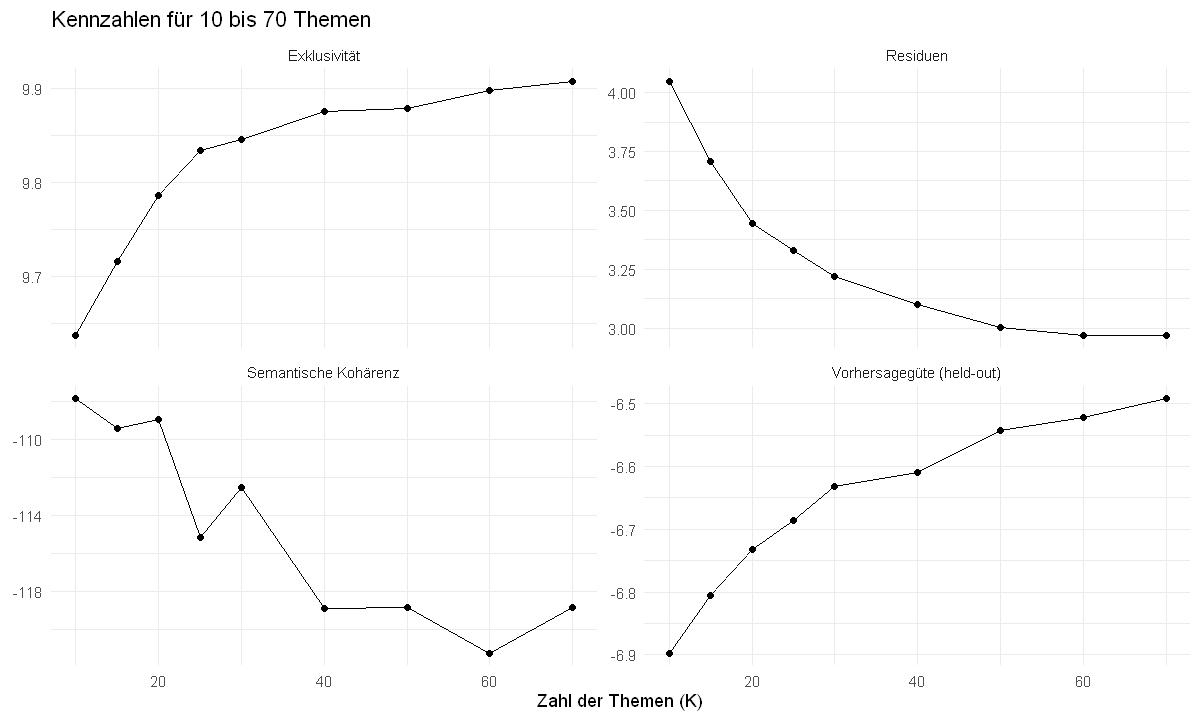

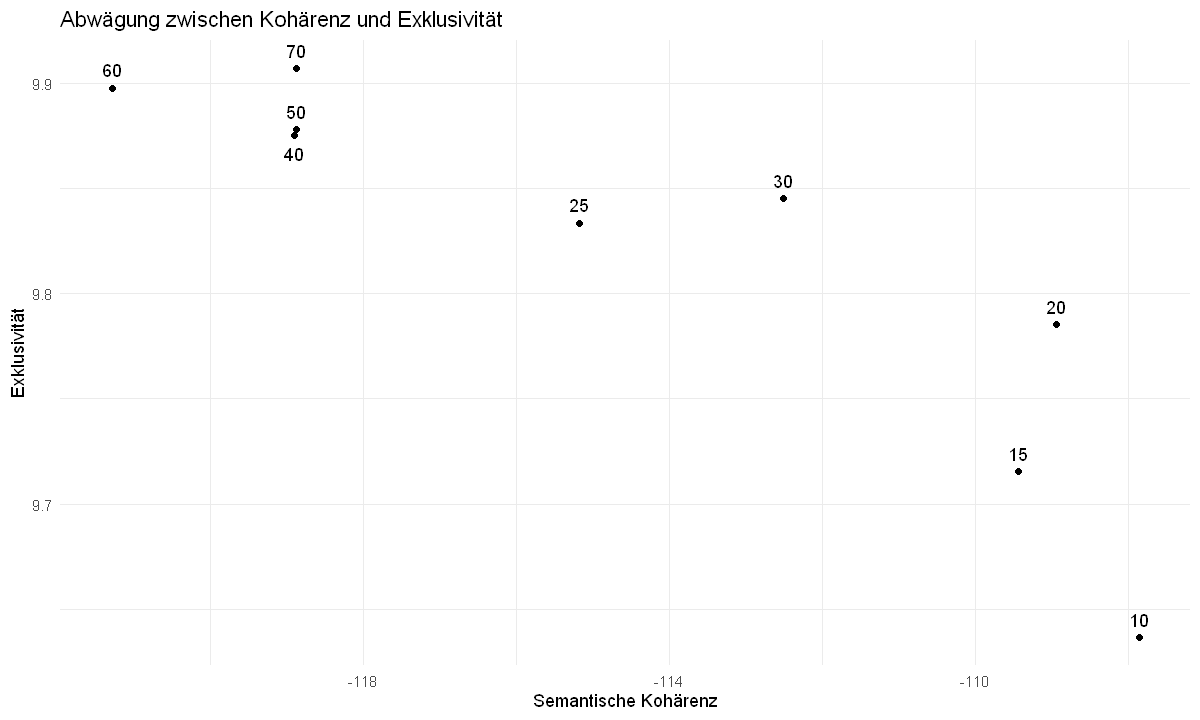

In [5]:
dir.create("figures", showWarnings = FALSE)
options(repr.plot.width = 10, repr.plot.height = 6)

lang <- data.frame(
  K = rep(ergebnis_k$K, 4),
  kennzahl = rep(c("Vorhersagegüte (held-out)", "Residuen",
                   "Semantische Kohärenz", "Exklusivität"), each = nrow(ergebnis_k)),
  wert = c(ergebnis_k$heldout, ergebnis_k$residual, ergebnis_k$semcoh, ergebnis_k$exclus)
)

abb_kennzahlen <- ggplot(lang, aes(K, wert)) +
  geom_line() +
  geom_point() +
  facet_wrap(~ kennzahl, scales = "free_y") +
  labs(x = "Zahl der Themen (K)", y = NULL,
       title = "Kennzahlen für 10 bis 70 Themen") +
  theme_minimal()
ggsave("figures/stm_kennzahlen_k.png", abb_kennzahlen, width = 10, height = 6, dpi = 150)
abb_kennzahlen

abb_abwaegung <- ggplot(ergebnis_k, aes(semcoh, exclus, label = K)) +
  geom_point() +
  geom_text(vjust = ifelse(ergebnis_k$K == 40, 1.8, -0.8)) +
  labs(x = "Semantische Kohärenz", y = "Exklusivität",
       title = "Abwägung zwischen Kohärenz und Exklusivität") +
  theme_minimal()
ggsave("figures/stm_kohaerenz_exklusivitaet.png", abb_abwaegung, width = 8, height = 6, dpi = 150)
abb_abwaegung

### 6. Schätzung der drei Kandidaten

Ich schätze die Modelle mit 20, 40 und 60 Themen vollständig, mit bis zu 500 Iterationen, damit sie konvergieren. Jedes Modell speichere ich einzeln. Im nächsten Abschnitt vergleiche ich die Themen der drei Modelle inhaltlich.

Liegt ein Modell schon als Datei vor, lädt die Zelle es, statt neu zu schätzen.

In [6]:
kandidaten <- c(20, 40, 60)
modelle <- list()

for (k in kandidaten) {
  datei <- sprintf("data/interim/stm_k%d.rds", k)
  if (file.exists(datei)) {
    modelle[[as.character(k)]] <- readRDS(datei)
    dauer <- "geladen"
  } else {
    zeit <- system.time(
      modelle[[as.character(k)]] <- stm(
        documents = stm_daten$documents,
        vocab = stm_daten$vocab,
        K = k,
        prevalence = ~ kapitel + s(jahr, df = 5),
        data = meta,
        init.type = "Spectral",
        max.em.its = 500,
        seed = 2026,
        verbose = FALSE
      )
    )
    saveRDS(modelle[[as.character(k)]], datei)
    dauer <- sprintf("%.1f Minuten", zeit[["elapsed"]] / 60)
  }
  cat(sprintf("K = %d: %s, %d Iterationen, konvergiert: %s\n",
              k, dauer,
              length(modelle[[as.character(k)]]$convergence$bound),
              modelle[[as.character(k)]]$convergence$converged))
}

K = 20: geladen, 48 Iterationen, konvergiert: TRUE
K = 40: geladen, 133 Iterationen, konvergiert: TRUE
K = 60: geladen, 107 Iterationen, konvergiert: TRUE


**Befund:** Alle drei Modelle sind konvergiert. Beim ersten Lauf dauerte die Schätzung für 20 Themen 1,3 Minuten (48 Iterationen), für 40 Themen 19,6 Minuten (133 Iterationen) und für 60 Themen 9,2 Minuten (107 Iterationen).

### 7. Themen der drei Kandidaten

Ich vergleiche die drei Modelle inhaltlich. Für jedes Thema zeige ich den Anteil am Korpus und die sechs FREX-Wörter. FREX gewichtet Wörter danach, wie häufig sie im Thema vorkommen und wie exklusiv sie für dieses Thema sind. Solche Wörter kennzeichnen ein Thema besser als die bloß häufigsten Wörter, die oft in vielen Themen auftauchen.

Ich prüfe drei Fragen:

1. Sind die Themen lesbar und klar voneinander abgegrenzt?
2. Treten neben den Bildungsbereichen der Kapitel auch Querschnittsthemen hervor, etwa Ungleichheit, Personal, Digitalisierung oder Steuerung?
3. Zerfallen Themen bei höherer Zahl in sinnvolle Unterthemen oder in kaum unterscheidbare Varianten?

Die Tabellen speichere ich zusätzlich als CSV-Dateien.

In [7]:
themen_tabelle <- function(modell) {
  frex <- labelTopics(modell, n = 6)$frex
  data.frame(
    thema = seq_len(ncol(modell$theta)),
    anteil = round(100 * colMeans(modell$theta), 1),
    frex = apply(frex, 1, paste, collapse = ", ")
  ) |>
    arrange(desc(anteil))
}

for (k in names(modelle)) {
  tabelle <- themen_tabelle(modelle[[k]])
  write.csv(tabelle, sprintf("data/processed/stm_themen_k%s.csv", k),
            row.names = FALSE, fileEncoding = "UTF-8")
  cat(sprintf("\n===== K = %s =====\n", k))
  cat(sprintf("Thema %2d (%.1f %%): %s\n", tabelle$thema, tabelle$anteil, tabelle$frex),
      sep = "")
}


===== K = 20 =====
Thema 14 (7.8 %): risikolage, eltern, kind, eingliederungshilfe, betreuen, vorlesen
Thema  3 (7.1 %): akteur, herausforderung, qualitativ, rahmenbedingung, behinderung, steuerung
Thema 17 (6.9 %): studienanfänger, masterstudium, studienangebot, studiendauer, semester, studiennachfrage
Thema  8 (5.9 %): mann, frau, erwerbsbeteiligung, bildungsabschluss, erwerbstätig, isced
Thema  2 (5.7 %): bericht, indikator, kapitel, bildungsbericht, darstellung, analysieren
Thema  5 (5.7 %): migrationshintergrund, zugewandert, schutz, generation, bevölkerung, migranten
Thema  4 (5.4 %): kaufmännisch, neuzugang, schulberufssystem, anr, ausbildungsanfänger, arbeitsagenturbezirk
Thema  7 (5.2 %): sonderpädagogisch, schulart, hauptschule, förderschule, förderschwerpunkt, schulangebot
Thema 11 (5.0 %): personal, personalbedarf, fachkraft, pädagogisch, tagespflegeperson, erzieher
Thema 19 (4.9 %): bayern, württemberg, stadtstaat, sachsen, nordrhein, westfalen
Thema  6 (4.6 %): anbieter,

**Entscheidung: 40 Themen als Hauptmodell.**

- **20 Themen sind zu grob.** Mehrere Themen vermischen Unzusammenhängendes: Behinderung mit Steuerung (Thema 3), musisch-ästhetische Bildung mit Bildungserträgen (1), die Pandemie mit Betrieben und Branchen (10).
- **40 Themen sind klar abgegrenzt** und zeigen die Querschnittsthemen als eigene Themen: soziale Herkunft und Ungleichheit (38), Steuerung und Governance (5), Qualitätssicherung und Programme (33), pädagogisches Personal (11) und Lehrkräfte (29), Digitalisierung (20), Zuwanderung und Flucht (25), Pandemie (21), Teilhabe und Chancengleichheit (37), Heterogenität und Anforderungen (22), Demografie (12), Stadt, Land und Ost-West (36), Datenlage (19).
- **60 Themen zerlegen vor allem die Bildungsbereiche weiter**, etwa das Studium in Studienberechtigte, Bachelor und Master sowie Fächergruppen. Einige Querschnittsthemen werden feiner, etwa Stadt und Land (7) getrennt von Ost und West (49).

Vier Themen beschreiben eher den Bericht als Inhalte: Verweise auf Konzept und Kapitel des Berichts (2, 28, 40) und Formulierungen von Trends ("anstieg, rückgang, verzeichnen", 24). Sie bleiben im Modell, damit sie diese Wörter aufnehmen, ich deute sie aber nicht inhaltlich.

Da die Kennzahlen zwischen 30 und 60 Themen nicht eindeutig trennen, prüfe ich die zentralen Ergebnisse später mit 30 und 60 Themen. Halten die Trends in beiden, hängen sie nicht an der gewählten Themenzahl.

### 8. Themen benennen

Die FREX-Wörter aus Abschnitt 7 zeigen, was ein Thema von den anderen unterscheidet. Für einen Namen reicht das nicht. Ich ziehe deshalb drei Quellen heran:

1. Prob-Wörter: die häufigsten Wörter eines Themas. Sie zeigen, worüber ein Thema spricht.
2. FREX-Wörter: Wörter, die häufig und zugleich exklusiv für ein Thema sind.
3. Typische Absätze: die zwei Absätze mit dem höchsten Anteil des Themas, mit Jahr und Kapitel.

Die Themen erscheinen nach ihrem Anteil am Korpus, das größte zuerst. Die Ausgabe zeigt Prob- und FREX-Wörter. Die typischen Absätze enthalten Text aus den Berichten. Ich schreibe sie deshalb nur in die Datei `data/interim/stm_k40_typische_absaetze.csv`, die nicht veröffentlicht wird. Aus ihr leite ich im nächsten Abschnitt Kurznamen und Gruppen ab: Bildungsbereich, Querschnittsthema oder Berichtssprache.

In [8]:
suppressPackageStartupMessages({
  library(stm)
  library(dplyr)
})

modell_k40 <- readRDS("data/interim/stm_k40.rds")
stm_daten <- readRDS("data/interim/stm_daten.rds")
dokumente <- readRDS("data/interim/dokumente.rds")

# Texte in der Reihenfolge der Modelldokumente
ids <- names(stm_daten$documents)
texte <- dokumente$text[match(ids, as.character(dokumente$absatz_id))]
stopifnot(length(texte) == length(stm_daten$documents), !anyNA(texte))

woerter <- labelTopics(modell_k40, n = 8)
anteil <- colMeans(modell_k40$theta)
typisch <- findThoughts(modell_k40, texts = texte, n = 2, topics = 1:40)

uebersicht <- bind_rows(lapply(1:40, function(k) {
  idx <- typisch$index[[k]]
  data.frame(
    thema = k,
    anteil = round(100 * anteil[k], 1),
    prob = paste(woerter$prob[k, ], collapse = ", "),
    frex = paste(woerter$frex[k, ], collapse = ", "),
    jahr = stm_daten$meta$jahr[idx],
    kapitel = stm_daten$meta$kapitel[idx],
    absatz = substr(gsub("\\s+", " ", texte[idx]), 1, 300)
  )
}))

write.csv(uebersicht, "data/interim/stm_k40_typische_absaetze.csv",
          row.names = FALSE, fileEncoding = "UTF-8")

for (k in order(anteil, decreasing = TRUE)) {
  t <- uebersicht[uebersicht$thema == k, ]
  cat(sprintf("\n=== Thema %d (%.1f Prozent) ===\n", k, t$anteil[1]))
  cat("Prob:", t$prob[1], "\n")
  cat("FREX:", t$frex[1], "\n")
}


=== Thema 23 (4.5 Prozent) ===
Prob: person, frau, migrationshintergrund, mann, bildungsstand, abschluss, unterschied, alter 
FREX: mann, frau, bildungsstand, migrationshintergrund, generation, hochschulabschluss, isced, erwerbsbeteiligung 

=== Thema 24 (4.2 Prozent) ===
Prob: anstieg, rückgang, prozentpunkt, leicht, entwicklung, anzahl, niveau, verzeichnen 
FREX: anstieg, verzeichnen, rückgang, leicht, zurückgehen, niveau, rückläufig, zunahme 

=== Thema 14 (3.8 Prozent) ===
Prob: kind, eltern, familie, risikolage, leben, erwerbstätigkeit, haushalt, mütter 
FREX: risikolage, vorlesen, mütter, familie, mutter, eltern, alleinerziehend, elternteil 

=== Thema 30 (3.7 Prozent) ===
Prob: kind, kindertageseinrichtung, einrichtung, angebot, platz, kindertagesbetreuung, westdeutschland, kita 
FREX: betreuen, platz, eingliederungshilfe, personalschlüssel, tageseinrichtung, schuleintritt, familiensprache, kita 

=== Thema 39 (3.3 Prozent) ===
Prob: studium, absolvent, studienberechtigte, hoch

### 9. Kurznamen und Gruppen der Themen

Aus Prob-Wörtern, FREX-Wörtern und typischen Absätzen (Abschnitt 8) vergebe ich jedem Thema einen Kurznamen und ordne es einer von drei Gruppen zu:

| Gruppe | Bedeutung | Themen |
|---|---|---|
| Bildungsbereich | entspricht einem Kapitel C bis G: frühe Bildung, Schule, berufliche Ausbildung, Hochschule, Weiterbildung | 14 |
| Querschnittsthema | tritt in mehreren Kapiteln auf, etwa soziale Herkunft, Personal, Finanzen, Digitalisierung | 18 |
| Berichtssprache | beschreibt Aufbau, Methode oder Veränderung, kein inhaltliches Thema | 8 |

Beobachtungen bei der Benennung:

- Die Berichtssprache umfasst knapp ein Fünftel des Korpus. Ich behalte diese Themen im Modell, weil sie Wortanteile binden, die sonst inhaltliche Themen verzerren würden. In Aussagen über inhaltlichen Wandel klammere ich sie aus.
- Zwei Themen der Berichtssprache tragen bewertende Sprache: T15 (Frage, Problem, Debatte) und T22 (Anforderung, Unterstützung, Aufgabe). Sie sind für die Frage nach Beschreibung, Bewertung und Handlungsbedarf relevant.
- T2, T28 und T40 stammen fast nur aus den Einleitungen, deren Text sich von Bericht zu Bericht wiederholt. Ihre Stabilität liegt am Berichtskonzept.
- T32 verbindet Ländernamen mit dem Thema Einschulung. Grund ist der Zerfall von Ländernamen mit Bindestrich ("baden", "württemberg"). Ich ordne T32 als Länderunterschiede ein.
- T21 (Corona-Pandemie) und T25 (Zuwanderung und Integration) beziehen sich auf zeitlich begrenzte Ereignisse. Sie sind Kandidaten für neu hinzukommende Themen.

Die Tabelle speichere ich unter `data/processed/stm_themen_k40_namen.csv`. Spätere Abschnitte nutzen die Kurznamen für Grafiken.

In [9]:
themen_namen <- tibble::tribble(
  ~thema, ~kurzname,                                    ~gruppe,             ~bereich,
   1, "Erträge und kulturelle Bildung",                 "Querschnittsthema", NA,
   2, "Berichtsaufbau und Indikatoren",                 "Berichtssprache",   NA,
   3, "Frühe Bildung allgemein",                        "Bildungsbereich",   "Frühe Bildung",
   4, "Ausbildungsberufe und Berufseinstieg",           "Bildungsbereich",   "Berufliche Ausbildung",
   5, "Steuerung des Bildungssystems",                  "Querschnittsthema", NA,
   6, "Weiterbildungsbeteiligung und Anbieter",         "Bildungsbereich",   "Weiterbildung",
   7, "Schularten im Sekundarbereich",                  "Bildungsbereich",   "Schule",
   8, "Arbeitsmarkt und Erwerbstätigkeit",              "Querschnittsthema", NA,
   9, "Bildungsausgaben",                               "Querschnittsthema", NA,
  10, "Betriebe in Aus- und Weiterbildung",             "Bildungsbereich",   "Berufliche Ausbildung",
  11, "Pädagogisches Personal",                         "Querschnittsthema", NA,
  12, "Demografischer und wirtschaftlicher Wandel",     "Querschnittsthema", NA,
  13, "Bildungswege, Durchlässigkeit, Abbruch",         "Querschnittsthema", NA,
  14, "Familie und soziale Risikolagen",                "Querschnittsthema", NA,
  15, "Problemsicht und Debatte",                       "Berichtssprache",   NA,
  16, "Internationaler Vergleich",                      "Querschnittsthema", NA,
  17, "Hochschulen und Studienangebot",                 "Bildungsbereich",   "Hochschule",
  18, "Ausbildungsmarkt und Übergangssystem",           "Bildungsbereich",   "Berufliche Ausbildung",
  19, "Datengrundlage und Studien",                     "Berichtssprache",   NA,
  20, "Digitalisierung",                                "Querschnittsthema", NA,
  21, "Corona-Pandemie",                                "Querschnittsthema", NA,
  22, "Anforderungen und Unterstützung",                "Berichtssprache",   NA,
  23, "Bildungsstand der Bevölkerung",                  "Querschnittsthema", NA,
  24, "Anstieg und Rückgang",                           "Berichtssprache",   NA,
  25, "Zuwanderung und Integration",                    "Querschnittsthema", NA,
  26, "Junge Erwachsene und Engagement",                "Querschnittsthema", NA,
  27, "Ganztag",                                        "Bildungsbereich",   "Schule",
  28, "Konzept der Bildungsberichterstattung",          "Berichtssprache",   NA,
  29, "Lehrkräfte",                                     "Bildungsbereich",   "Schule",
  30, "Kindertagesbetreuung",                           "Bildungsbereich",   "Frühe Bildung",
  31, "Studium und Bologna-Reform",                     "Bildungsbereich",   "Hochschule",
  32, "Länderunterschiede",                             "Querschnittsthema", NA,
  33, "Programme und Qualitätssicherung",               "Querschnittsthema", NA,
  34, "Sonderpädagogische Förderung und Inklusion",     "Bildungsbereich",   "Schule",
  35, "Schulabschlüsse",                                "Bildungsbereich",   "Schule",
  36, "Regionale Unterschiede, Ost und West",           "Querschnittsthema", NA,
  37, "Bildungsziele und Teilhabe",                     "Berichtssprache",   NA,
  38, "Soziale Herkunft und Ungleichheit",              "Querschnittsthema", NA,
  39, "Studienberechtigung und Hochschulabschluss",     "Bildungsbereich",   "Hochschule",
  40, "Einleitung des Berichts",                        "Berichtssprache",   NA
)

themen_namen <- themen_namen |>
  mutate(anteil_prozent = round(100 * .env$anteil[thema], 1)) |>
  arrange(gruppe, desc(anteil_prozent))

write.csv(themen_namen, "data/processed/stm_themen_k40_namen.csv",
          row.names = FALSE, fileEncoding = "UTF-8")

print(themen_namen |>
        group_by(gruppe) |>
        summarise(themen = n(), anteil_prozent = sum(anteil_prozent)))
print(themen_namen, n = 40)

# A tibble: 3 × 3
  gruppe            themen anteil_prozent
  <chr>              <int>          <dbl>
1 Berichtssprache        8           17.8
2 Bildungsbereich       14           35.5
3 Querschnittsthema     18           46.7
# A tibble: 40 × 5
   thema kurzname                                  gruppe bereich anteil_prozent
   <dbl> <chr>                                     <chr>  <chr>            <dbl>
 1    24 Anstieg und Rückgang                      Beric… NA                 4.2
 2     2 Berichtsaufbau und Indikatoren            Beric… NA                 2.9
 3    15 Problemsicht und Debatte                  Beric… NA                 2.4
 4    19 Datengrundlage und Studien                Beric… NA                 2.2
 5    22 Anforderungen und Unterstützung           Beric… NA                 2.2
 6    37 Bildungsziele und Teilhabe                Beric… NA                 2.2
 7    28 Konzept der Bildungsberichterstattung     Beric… NA                 1.1
 8    40 Einleitung des 

### 10. Themenanteile über die Zeit

Ich schätze, wie der Anteil jedes Themas vom Erscheinungsjahr abhängt. Grundlage ist dieselbe Formel wie im Modell: Kapitel als Kovariate und das Jahr als Spline mit fünf Freiheitsgraden. Der Spline erlaubt nicht lineare Verläufe, etwa einen Anstieg und späteren Rückgang.

Weil das Kapitel im Modell steckt, misst der Zeiteffekt Veränderungen bei gegebenem Kapitel. Ein Thema wächst also nicht schon deshalb, weil ein Kapitel in späteren Berichten mehr Seiten hat.

Die Unsicherheit der Themenschätzung geht über das Verfahren "Global" ein: estimateEffect zieht wiederholt Themenanteile aus dem Modell und schätzt die Regression für jede Ziehung neu.

Für jedes Thema berechne ich den geschätzten Anteil in jedem Berichtsjahr mit 95-Prozent-Intervall. Die Tabelle zeigt die inhaltlichen Themen (ohne Berichtssprache), sortiert nach der Veränderung von 2006 bis 2026. Als deutlich markiere ich eine Veränderung, wenn sich die Intervalle von 2006 und 2026 nicht überschneiden. Werte am Rand des Zeitraums sind bei Splines unsicherer, deshalb zeige ich zusätzlich das Jahr mit dem höchsten Anteil.

In [10]:
set.seed(2026)
zeit <- system.time(
  effekt_k40 <- estimateEffect(1:40 ~ kapitel + s(jahr, df = 5), modell_k40,
                               metadata = stm_daten$meta, uncertainty = "Global")
)
saveRDS(effekt_k40, "data/interim/stm_effekt_k40.rds")
cat("Laufzeit:", round(zeit[["elapsed"]] / 60, 1), "Minuten\n\n")

# Geschätzter Anteil je Thema in den 11 Berichtsjahren 2006, 2008, ..., 2026
verlauf <- bind_rows(lapply(1:40, function(k) {
  p <- plot(effekt_k40, covariate = "jahr", model = modell_k40,
            method = "continuous", topics = k, npoints = 11, omit.plot = TRUE)
  data.frame(thema = k, jahr = round(p$x),
             anteil = 100 * p$means[[1]],
             unten = 100 * p$ci[[1]][1, ],
             oben = 100 * p$ci[[1]][2, ])
}))
write.csv(verlauf, "data/processed/stm_k40_verlauf.csv",
          row.names = FALSE, fileEncoding = "UTF-8")

veraenderung <- verlauf |>
  group_by(thema) |>
  summarise(
    anteil_2006 = anteil[jahr == min(jahr)],
    anteil_2026 = anteil[jahr == max(jahr)],
    differenz = anteil_2026 - anteil_2006,
    deutlich = unten[jahr == max(jahr)] > oben[jahr == min(jahr)] |
               oben[jahr == max(jahr)] < unten[jahr == min(jahr)],
    hoechstes_jahr = jahr[which.max(anteil)],
    .groups = "drop"
  ) |>
  left_join(themen_namen |> select(thema, kurzname, gruppe), by = "thema") |>
  filter(gruppe != "Berichtssprache") |>
  mutate(across(c(anteil_2006, anteil_2026, differenz), \(x) round(x, 1))) |>
  arrange(desc(differenz))

print(veraenderung |> select(thema, kurzname, anteil_2006, anteil_2026,
                             differenz, deutlich, hoechstes_jahr), n = 32)

Laufzeit: 0.1 Minuten

# A tibble: 32 × 7
   thema kurzname      anteil_2006 anteil_2026 differenz deutlich hoechstes_jahr
   <dbl> <chr>               <dbl>       <dbl>     <dbl> <lgl>             <dbl>
 1     5 Steuerung de…         2.6         8.1       5.5 TRUE               2026
 2    33 Programme un…         4.6         8.2       3.5 TRUE               2026
 3    38 Soziale Herk…         6.3         8.7       2.4 TRUE               2026
 4    26 Junge Erwach…         0.8         2.6       1.8 TRUE               2026
 5    20 Digitalisier…         4.5         6.1       1.6 FALSE              2020
 6    25 Zuwanderung …         1.1         2.5       1.4 TRUE               2024
 7     3 Frühe Bildun…         1.1         2.4       1.3 TRUE               2026
 8    29 Lehrkräfte            1.5         2.8       1.3 TRUE               2024
 9    14 Familie und …         0.7         1.7       1   FALSE              2024
10    17 Hochschulen …         0.9         1.6       0.7 FALSE     

**Befund zu Abschnitt 10.** Die Schätzung dauert wenige Sekunden. Nach der Tabelle steigen Steuerung des Bildungssystems (plus 5,5 Prozentpunkte von 2006 bis 2026), Programme und Qualitätssicherung (plus 3,5) und soziale Herkunft und Ungleichheit (plus 2,4) am stärksten. Am stärksten sinken Bildungsstand der Bevölkerung und internationaler Vergleich (je minus 3,6) sowie Schularten im Sekundarbereich (minus 2,1).

Drei Einschränkungen gelten für diese Tabelle:

- Die absoluten Werte sind keine Anteile am Korpus. Die Schätzung hält das Kapitel auf einem festen Wert. Weil das Modell Kapitel und Jahr additiv verbindet, ist der Zeitverlauf für alle Kapitel gleich. Deuten lassen sich deshalb nur die Differenzen.
- Das Modell ist eine lineare Regression auf Anteile und erlaubt Werte unter null. Corona zeigt deshalb negative Werte.
- Der Spline glättet kurze Ereignisse. Corona und Zuwanderung erreichen ihren Höchstwert laut Spline erst 2024, obwohl die Berichte das Thema 2022 und 2016 am stärksten behandeln.

Abschnitt 11 prüft die Befunde deshalb an den beobachteten Anteilen.

### 11. Prüfung an den beobachteten Themenanteilen

Der Spline in Abschnitt 10 glättet den Verlauf. Zwei Befunde prüfe ich deshalb an den beobachteten Anteilen: dem Mittelwert der Themenanteile aller Absätze eines Berichts, ohne Regressionsmodell.

1. Ereignisartige Themen (Corona, Zuwanderung): Liegt der Höchstwert im erwarteten Jahr?
2. Steuerung des Bildungssystems (T5): Beide typischen Absätze stammen aus dem Teil "Zentrale Herausforderungen", den der Überblick erst 2026 enthält. Ich prüfe, ob der Anstieg auch ohne den Überblick (Kapitel UEB) besteht.

In [11]:
theta <- as.data.frame(modell_k40$theta)
names(theta) <- paste0("T", 1:40)
beobachtet <- cbind(stm_daten$meta[, c("jahr", "kapitel")], theta)

# Mittlerer Anteil je Bericht für ausgewählte Themen
auswahl <- paste0("T", c(5, 33, 38, 23, 16, 7, 18, 21, 25))
cat("Beobachtete Anteile in Prozent, alle Kapitel:\n")
print(beobachtet |>
        group_by(jahr) |>
        summarise(across(all_of(auswahl), \(x) round(100 * mean(x), 1))),
      width = Inf)

# Thema 5 mit und ohne Überblick
cat("\nThema 5 (Steuerung) in Prozent, mit und ohne Kapitel UEB:\n")
print(beobachtet |>
        group_by(jahr) |>
        summarise(mit_ueb = round(100 * mean(T5), 1),
                  ohne_ueb = round(100 * mean(T5[kapitel != "UEB"]), 1)))

# Thema 5 im Bericht 2026 nach Kapitel
cat("\nThema 5 im Bericht 2026 nach Kapitel:\n")
print(beobachtet |>
        filter(jahr == 2026) |>
        group_by(kapitel) |>
        summarise(dokumente = n(),
                  summe = round(sum(T5), 1),
                  mittel = round(100 * mean(T5), 1)) |>
        arrange(desc(summe)))

Beobachtete Anteile in Prozent, alle Kapitel:
# A tibble: 11 × 10
    jahr    T5   T33   T38   T23   T16    T7   T18   T21   T25
   <dbl> <dbl> <dbl> <dbl> <dbl> <dbl> <dbl> <dbl> <dbl> <dbl>
 1  2006   1.3   1.4   5     6.3   6.1   4.5   3.5   0.5   0.6
 2  2008   0.8   0.9   2.4   4.3   4.4   3.3   6.1   0.5   0.3
 3  2010   0.9   0.7   2.2   5.9   3.6   2.7   4.3   0.7   0.4
 4  2012   0.9   0.9   2     5.8   2.7   2.6   2.9   0.4   0.5
 5  2014   1.1   2     2.2   5.2   3.4   3.2   3.3   0.3   1.1
 6  2016   1.1   1.5   3.3   6.7   2.7   3     2.7   0.3   3.9
 7  2018   1.5   1.4   2.4   5.4   1.9   3.6   2.7   0.4   1.9
 8  2020   1.4   1.5   2.3   3.6   2.3   3.3   2.2   1.1   1.5
 9  2022   1.8   3     2.6   3.3   1.9   1.5   2.1   5     1.8
10  2024   3.6   4.6   2.2   3.1   1.5   1.4   3.5   1.9   2.6
11  2026   8.6   5.3   7.6   2.6   2.2   1.5   1.9   1.1   2.2

Thema 5 (Steuerung) in Prozent, mit und ohne Kapitel UEB:
# A tibble: 11 × 3
    jahr mit_ueb ohne_ueb
   <dbl>   

#### Ergebnis der Prüfung

Der Spline gibt langsame Trends wieder, glättet aber Ereignisse und Sprünge weg:

- Corona erreicht den Höchstwert 2022 (5,0 Prozent), Zuwanderung 2016 (3,9 Prozent). Der Spline verlegt beide nach 2024. Für ereignisartige Themen nutze ich die beobachteten Anteile.
- Steuerung des Bildungssystems (T5) liegt bis 2022 auch ohne Überblick bei rund 1 Prozent und steigt erst 2024 (3,1) und 2026 (4,6). Im Bericht 2026 stammt gut die Hälfte des Themas aus dem Überblick, ein weiteres Fünftel aus dem Schwerpunktkapitel H. Der Anstieg ist real, aber jung und an zwei Kapitel gebunden.
- Soziale Herkunft (T38) folgt einem U-Verlauf: 5,0 Prozent 2006, danach 2,0 bis 3,3 Prozent, 2026 dann 7,6 Prozent.
- Ohne Sprung sinken Bildungsstand der Bevölkerung (6,3 auf 2,6) und internationaler Vergleich (6,1 auf 2,2). Programme und Qualitätssicherung steigen ab 2022. Schularten im Sekundarbereich fallen 2022 abrupt von 3,3 auf 1,5.

Zwei Kapitel verzerren die Jahresmittel: Das Schwerpunktkapitel H wechselt sein Thema mit jedem Bericht, und der Überblick schwankt im Umfang zwischen 13 (2014) und 191 Dokumenten (2026).

### 12. Visualisierung der Themenentwicklung

Fünf Abbildungen zeigen, wie sich die Themen über die elf Berichte entwickeln. Alle beruhen auf den beobachteten Anteilen: dem Mittelwert der Themenanteile aller Absätze eines Berichts. Den Spline aus Abschnitt 10 nutze ich hier nicht, weil er Ereignisse und Sprünge glättet (Abschnitt 11).

| Abbildung | Frage |
|---|---|
| 1 | Wie groß sind die Berichte, und wie verteilt sich ihr Umfang auf die Kapitel? |
| 2 | Welche Themen gewinnen oder verlieren über 20 Jahre an Gewicht? |
| 3 | Wie verschiebt sich das Gewicht zwischen Bildungsbereichen, Querschnittsthemen und Berichtssprache? |
| 4 | Wie verlaufen ausgewählte Themen im Detail, und ändert sich das Bild ohne Schwerpunktkapitel und Überblick? |
| 5 | Aus welchen Teilen des Berichts stammen die auffälligen Anstiege? |

Ich unterscheide vier Kapitelgruppen:

- Kernkapitel: A bis G und I, die fortgeschriebenen Indikatoren
- Schwerpunktkapitel H: wechselt das Thema mit jedem Bericht
- Überblick (UEB): "Wichtige Ergebnisse im Überblick", 2026 mit den "Zentralen Herausforderungen"
- Einleitung (EIN)

Die erste Zelle lädt die Pakete und bringt die Themenanteile in ein langes Format: eine Zeile je Absatz und Thema.

In [12]:
for (paket in c("ggplot2", "tidyr")) {
  if (!requireNamespace(paket, quietly = TRUE)) install.packages(paket)
}
suppressPackageStartupMessages({
  library(ggplot2)
  library(tidyr)
})
dir.create("figures", showWarnings = FALSE)

farben_kapitel <- c("Kernkapitel" = "#9e9e9e", "Schwerpunkt H" = "#e07b39",
                    "Überblick" = "#1f4e79", "Einleitung" = "#c9d6e3")
quelle <- "Quelle: Bildung in Deutschland 2006 bis 2026, Structural Topic Model mit 40 Themen, eigene Auswertung"

lang <- beobachtet |>
  mutate(dok = row_number(),
         kapitelgruppe = case_when(
           kapitel == "H" ~ "Schwerpunkt H",
           kapitel == "UEB" ~ "Überblick",
           kapitel == "EIN" ~ "Einleitung",
           TRUE ~ "Kernkapitel")) |>
  pivot_longer(starts_with("T"), names_to = "thema", values_to = "theta") |>
  mutate(thema = as.integer(sub("T", "", thema))) |>
  left_join(themen_namen |> select(thema, kurzname, gruppe), by = "thema") |>
  mutate(label = paste0("T", thema, " ", kurzname))

n_jahr <- beobachtet |> count(jahr, name = "n_jahr")
cat("Zeilen:", nrow(lang), "(", nrow(beobachtet), "Absätze x 40 Themen )\n")

Zeilen: 365000 ( 9125 Absätze x 40 Themen )


#### Abbildung 1: Umfang der Berichte nach Kapitelgruppe

Jeder Balken zeigt die Zahl der Absätze eines Berichts, aufgeteilt nach Kapitelgruppe.

So liest man die Abbildung: Der graue Anteil (Kernkapitel) ist das, was jeder Bericht fortschreibt. Orange (Schwerpunktkapitel H) und Blau (Überblick) schwanken von Bericht zu Bericht. Je größer ihr Anteil in einem Jahr, desto stärker prägt der Schwerpunkt dieses Jahres das Jahresmittel aller Themen.

# A tibble: 11 × 5
    jahr Einleitung Kernkapitel `Schwerpunkt H` Überblick
   <dbl>      <int>       <int>           <int>     <int>
 1  2006         21         486             153        44
 2  2008         34         514             141        64
 3  2010         19         476             153        55
 4  2012         20         529             149        64
 5  2014         12         532             153        13
 6  2016         16         511             165        61
 7  2018         15         526             159        88
 8  2020         16         617             214        79
 9  2022         17         657             239        98
10  2024         18         656             256        90
11  2026         16         623             165       191


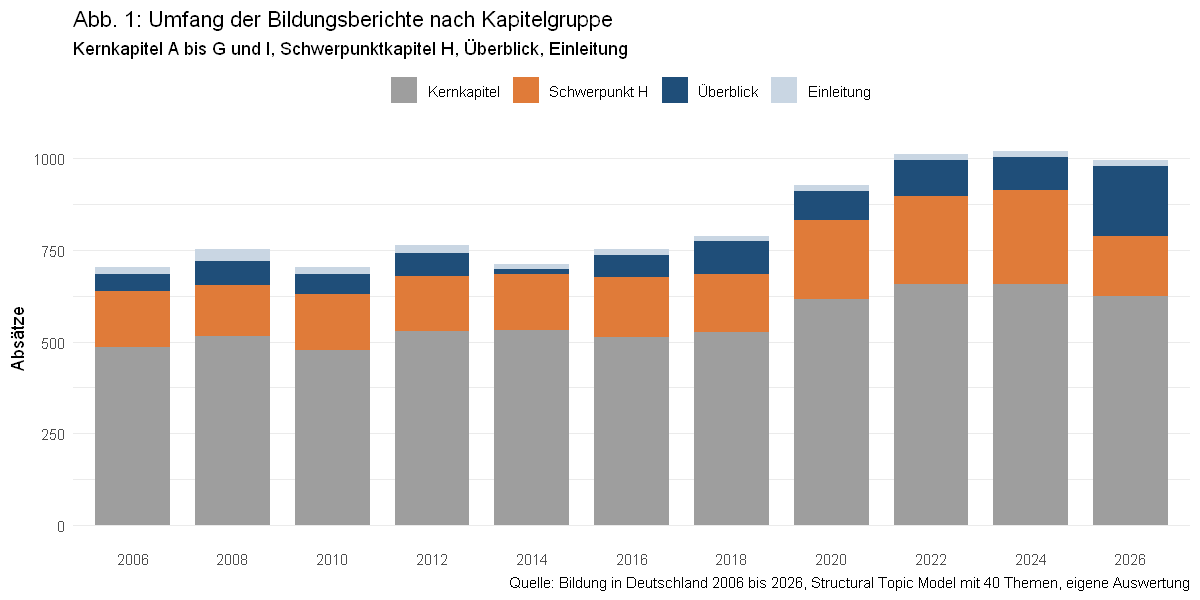

In [13]:
options(repr.plot.width = 10, repr.plot.height = 5)

dok_jahr <- lang |>
  distinct(dok, jahr, kapitelgruppe) |>
  count(jahr, kapitelgruppe) |>
  mutate(kapitelgruppe = factor(kapitelgruppe, levels = rev(names(farben_kapitel))))

abb1 <- ggplot(dok_jahr, aes(factor(jahr), n, fill = kapitelgruppe)) +
  geom_col(width = 0.75) +
  scale_fill_manual(values = farben_kapitel, name = NULL, breaks = names(farben_kapitel)) +
  labs(x = NULL, y = "Absätze",
       title = "Abb. 1: Umfang der Bildungsberichte nach Kapitelgruppe",
       subtitle = "Kernkapitel A bis G und I, Schwerpunktkapitel H, Überblick, Einleitung",
       caption = quelle) +
  theme_minimal(base_size = 11) +
  theme(legend.position = "top", panel.grid.major.x = element_blank())

ggsave("figures/abb1_umfang_kapitelgruppen.png", abb1, width = 10, height = 5, dpi = 300)
abb1

print(dok_jahr |> pivot_wider(names_from = kapitelgruppe, values_from = n, values_fill = 0))

#### Themen der Schwerpunktkapitel

Mehrere Spitzen in den folgenden Abbildungen gehen auf das Schwerpunktkapitel H zurück. Damit die Zuordnung belegt ist, gebe ich für jeden Bericht die erste Überschrift des Kapitels H aus.

Für 2018 ist die erste Überschrift eine Unterüberschrift ("Konzeptionelle und empirische Bezugspunkte"). Der Titel des Kapitels lautet "Wirkungen und Erträge von Bildung".

In [14]:
print(dokumente |>
        filter(kapitel == "H", ueberschrift != "") |>
        group_by(jahr) |>
        slice(1) |>
        ungroup() |>
        transmute(jahr, titel = substr(ueberschrift, 1, 120)),
      n = 11, width = Inf)

# A tibble: 11 × 2
    jahr
   <dbl>
 1  2006
 2  2008
 3  2010
 4  2012
 5  2014
 6  2016
 7  2018
 8  2020
 9  2022
10  2024
11  2026
   titel                                                                        
   <chr>                                                                        
 1 1. Die Bedeutung der Migration für das Bildungswesen                         
 2 Perspektiven | Übergänge: Schule – Berufsausbildung – Hochschule – Arbeitsma…
 3 Perspektiven des Bildungswesens im demografischen Wandel                     
 4 Kulturelle/musisch-ästhetische Bildung im Lebenslauf                         
 5 Menschen mit Behinderungen im Bildungssystem                                 
 6 Bildung und Migration                                                        
 7 Konzeptionelle und empirische Bezugspunkte                                   
 8 Bildung in einer digitalisierten Welt                                        
 9 Bildungspersonal: Struktur, Entwicklung, Qualität u

Befund zu Abbildung 1. Die Berichte wachsen von rund 700 Absätzen (2006) auf rund 1.000 (ab 2022). Den Sprung 2020 tragen zwei Teile: die Kernkapitel (von rund 520 auf rund 620 Absätze) und das Schwerpunktkapitel H (2020 bis 2024 jeweils rund 210 bis 250 Absätze, vorher rund 140 bis 165). Am stärksten schwankt der Überblick: 13 Absätze 2014, 191 Absätze 2026. 2026 macht er rund ein Fünftel des Berichts aus. Die 13 Absätze 2014 gehen auf die defekt kodierten Aufzählungspunkte in diesem Bericht zurück.

Für die Analyse heißt das: Jahresmittel über alle Kapitel mischen fortgeschriebene Indikatoren mit wechselnden Schwerpunkten, und das Gewicht der Schwerpunkte ist seit 2020 gewachsen.

#### Abbildung 2: Alle inhaltlichen Themen im Zeitverlauf

Die Heatmap zeigt die 32 inhaltlichen Themen, ohne Berichtssprache. Jede Zeile ist ein Thema, jede Spalte ein Bericht. Die Zahl im Feld ist der mittlere Anteil des Themas an den Absätzen dieses Berichts in Prozent. Je dunkler das Feld, desto größer der Anteil.

Die Themen sind nach ihrem linearen Trend sortiert: oben die Themen mit dem stärksten Anstieg, unten die mit dem stärksten Rückgang.

So liest man die Abbildung:

- Ein Verlauf von hell nach dunkel in einer Zeile zeigt ein wachsendes Thema.
- Ein einzelnes dunkles Feld zeigt ein Ereignis oder einen Schwerpunkt in genau einem Bericht.
- Gleichmäßige Färbung zeigt ein Thema, das der Bericht konstant fortschreibt.

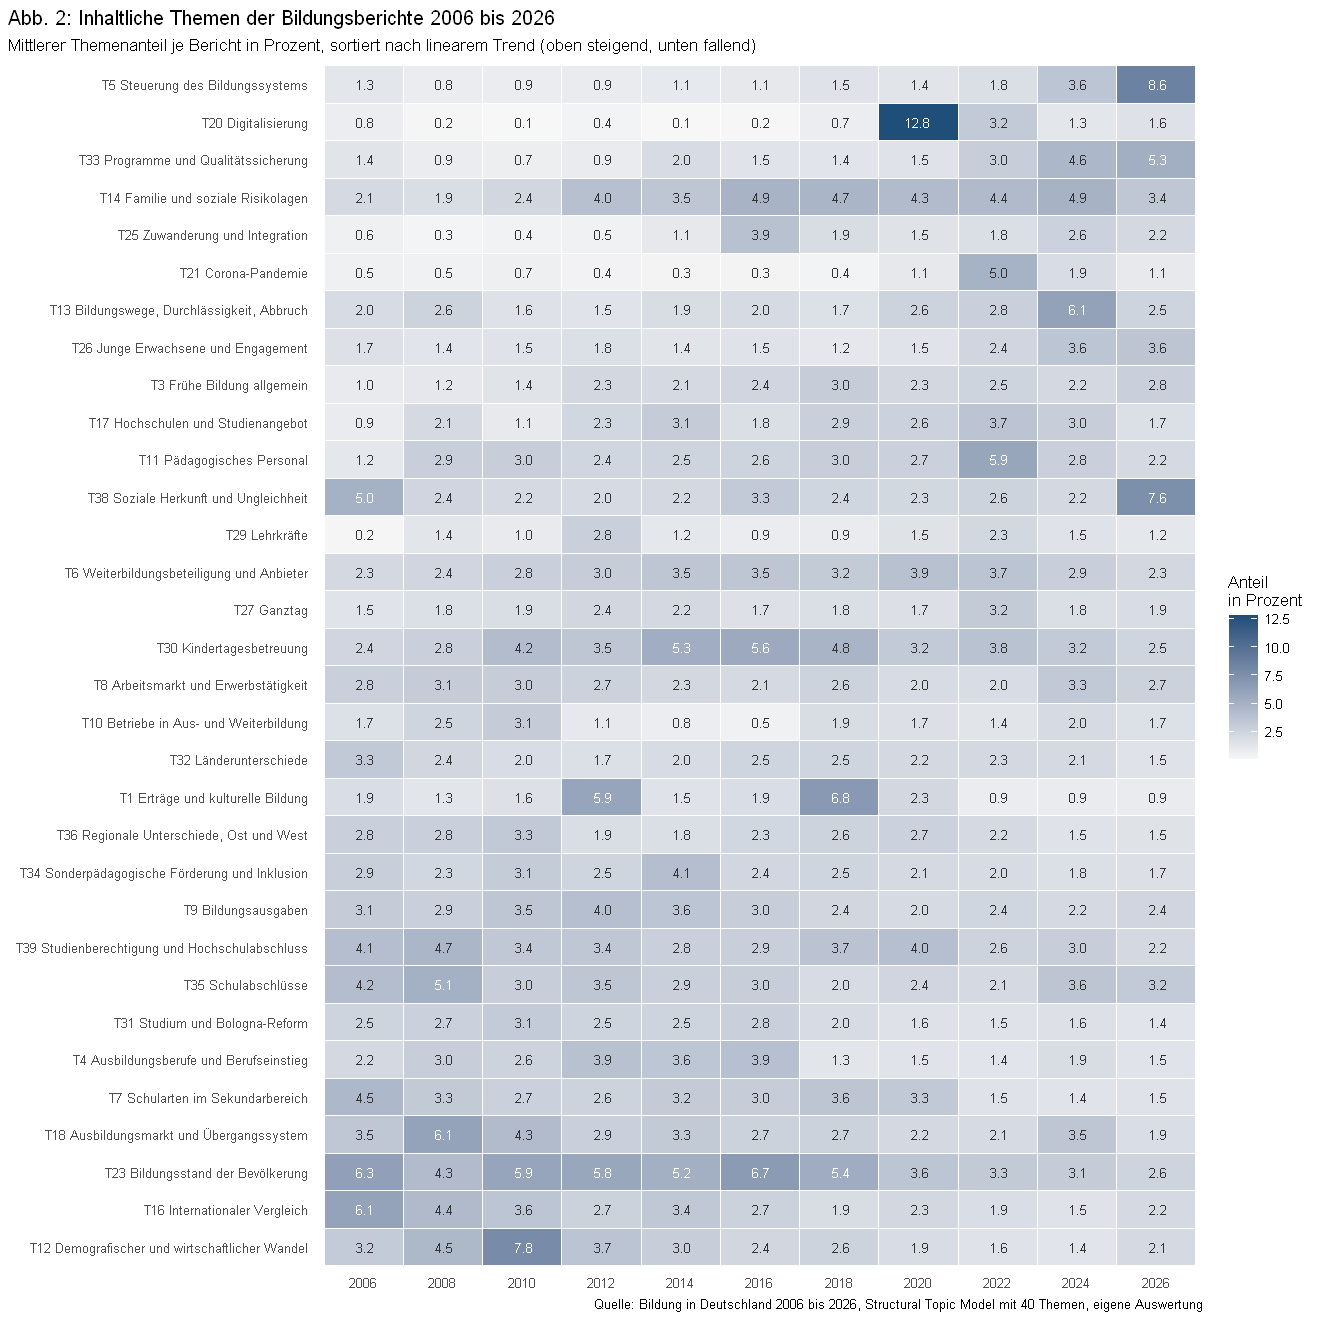

In [15]:
options(repr.plot.width = 11, repr.plot.height = 11)

jahresmittel <- lang |>
  filter(gruppe != "Berichtssprache") |>
  group_by(thema, label, jahr) |>
  summarise(anteil = 100 * mean(theta), .groups = "drop")

reihenfolge <- jahresmittel |>
  group_by(label) |>
  summarise(steigung = coef(lm(anteil ~ jahr))[2], .groups = "drop") |>
  arrange(steigung)
jahresmittel$label <- factor(jahresmittel$label, levels = reihenfolge$label)

abb2 <- ggplot(jahresmittel, aes(factor(jahr), label, fill = anteil)) +
  geom_tile(colour = "white", linewidth = 0.4) +
  geom_text(aes(label = format(round(anteil, 1), nsmall = 1),
                colour = anteil > 5), size = 2.7, show.legend = FALSE) +
  scale_fill_gradient(low = "#f7f7f7", high = "#1f4e79", name = "Anteil\nin Prozent") +
  scale_colour_manual(values = c("FALSE" = "grey20", "TRUE" = "white")) +
  labs(x = NULL, y = NULL,
       title = "Abb. 2: Inhaltliche Themen der Bildungsberichte 2006 bis 2026",
       subtitle = "Mittlerer Themenanteil je Bericht in Prozent, sortiert nach linearem Trend (oben steigend, unten fallend)",
       caption = quelle) +
  theme_minimal(base_size = 10) +
  theme(panel.grid = element_blank(), plot.title.position = "plot")

ggsave("figures/abb2_heatmap_themen.png", abb2, width = 11, height = 11, dpi = 300)
abb2

Befund zu Abbildung 2. Die Heatmap zeigt drei Muster.

1. Einzelne dunkle Felder. Jedes fällt auf das Schwerpunktkapitel H des jeweiligen Berichts, wie die Titel in der Tabelle oben belegen:

| Jahr | Schwerpunktkapitel H | Spitze |
|---|---|---|
| 2006 | Migration | soziale Herkunft (5,0) |
| 2008 | Übergänge | Ausbildungsmarkt (6,1) |
| 2010 | Demografischer Wandel | demografischer Wandel (7,8) |
| 2012 | Kulturelle/musisch-ästhetische Bildung | Erträge und kulturelle Bildung (5,9) |
| 2014 | Menschen mit Behinderungen | sonderpädagogische Förderung (4,1) |
| 2016 | Bildung und Migration | Zuwanderung (3,9) |
| 2018 | Wirkungen und Erträge von Bildung | Erträge und kulturelle Bildung (6,8) |
| 2020 | Bildung in einer digitalisierten Welt | Digitalisierung (12,8) |
| 2022 | Bildungspersonal | pädagogisches Personal (5,9) |
| 2024 | Berufliche Bildung | Bildungswege und Abbruch (6,1) |
| 2026 | Bildungsungleichheiten nach sozialer Herkunft | soziale Herkunft (7,6) |

2. Allmähliche Verschiebungen. Es steigen Programme und Qualitätssicherung, frühe Bildung, Familie und soziale Risikolagen (von rund 2 auf 4 bis 5 Prozent ab 2012) sowie junge Erwachsene und Engagement (auf 3,6 ab 2024). Es sinken internationaler Vergleich (6,1 auf 2,2), Bildungsstand der Bevölkerung (6,3 auf 2,6), Studienberechtigung und Hochschulabschluss (4,1 auf 2,2), Studium und Bologna-Reform (2,5 bis 3,1 auf 1,4) und Bildungsausgaben (4,0 im Jahr 2012 auf 2,4).
3. Gleichmäßige Zeilen. Arbeitsmarkt, Weiterbildungsbeteiligung und Ganztag schreibt der Bericht ohne große Ausschläge fort.

Ein Sonderfall ist die Digitalisierung: Nach der Spitze 2020 bleibt sie erhöht (1,3 bis 3,2 Prozent gegenüber höchstens 0,8 vor 2020). Das Schwerpunktthema ist in die Fortschreibung eingegangen.

Das Thema "Erträge und kulturelle Bildung" (T1) vereint zwei Inhalte, die das Modell zusammenlegt: Bildungserträge (Schwerpunkt 2018) und kulturelle Bildung (Schwerpunkt 2012). Darauf weisen die FREX-Wörter "ästhetisch" und "musisch" neben "ertrag" hin.

Die Sortierung nach linearem Trend reagiert auf einzelne Spitzen. Digitalisierung steht deshalb weit oben, obwohl der Anstieg vor allem aus einem Bericht stammt.

#### Abbildung 3: Gewicht der Themengruppen

Die 40 Themen lassen sich in drei Gruppen einteilen:

- Bildungsbereiche: Themen zu einer Bildungsstufe, etwa Kita, Schule oder Hochschule
- Querschnittsthemen: Themen, die mehrere Bildungsbereiche betreffen, etwa soziale Herkunft oder Digitalisierung
- Berichtssprache: Wörter, die der Bericht überall braucht, etwa Daten, Erhebung oder Vergleich

Die Flächen zeigen, welcher Anteil eines Berichts auf jede Gruppe entfällt. Zusammen ergeben die drei Flächen 100 Prozent. So wird sichtbar, ob die Berichte über die Jahre mehr über einzelne Bildungsbereiche oder mehr über übergreifende Themen schreiben.

Das linke Feld zeigt alle Kapitel, das rechte nur die Kernkapitel A bis G und I. Unterscheiden sich die beiden Felder in einem Jahr deutlich, verschieben das Schwerpunktkapitel H oder der Überblick das Gewicht der Gruppen in diesem Bericht.

# A tibble: 6 × 13
  basis                         gruppe            `2006` `2008` `2010` `2012`
  <chr>                         <fct>              <dbl>  <dbl>  <dbl>  <dbl>
1 Alle Kapitel                  Berichtssprache     20     19.1   18.1   18  
2 Alle Kapitel                  Bildungsbereich     34     41.3   37.8   38.8
3 Alle Kapitel                  Querschnittsthema   46     39.6   44.1   43.2
4 Nur Kernkapitel A bis G und I Berichtssprache     17     15.8   14.6   16.1
5 Nur Kernkapitel A bis G und I Bildungsbereich     38.8   40.7   40.9   40.4
6 Nur Kernkapitel A bis G und I Querschnittsthema   44.3   43.5   44.5   43.5
  `2014` `2016` `2018` `2020` `2022` `2024` `2026`
   <dbl>  <dbl>  <dbl>  <dbl>  <dbl>  <dbl>  <dbl>
1   20.4   18.1   18     15     16.9   16.6   18.5
2   40.5   37.1   36.3   34.2   33.8   33.5   27.6
3   39.1   44.8   45.7   50.8   49.2   49.8   53.9
4   16.9   15.4   16.3   14.1   16     15.5   17.8
5   40.8   41.1   42.9   40.3   34.1   34.8   33.5


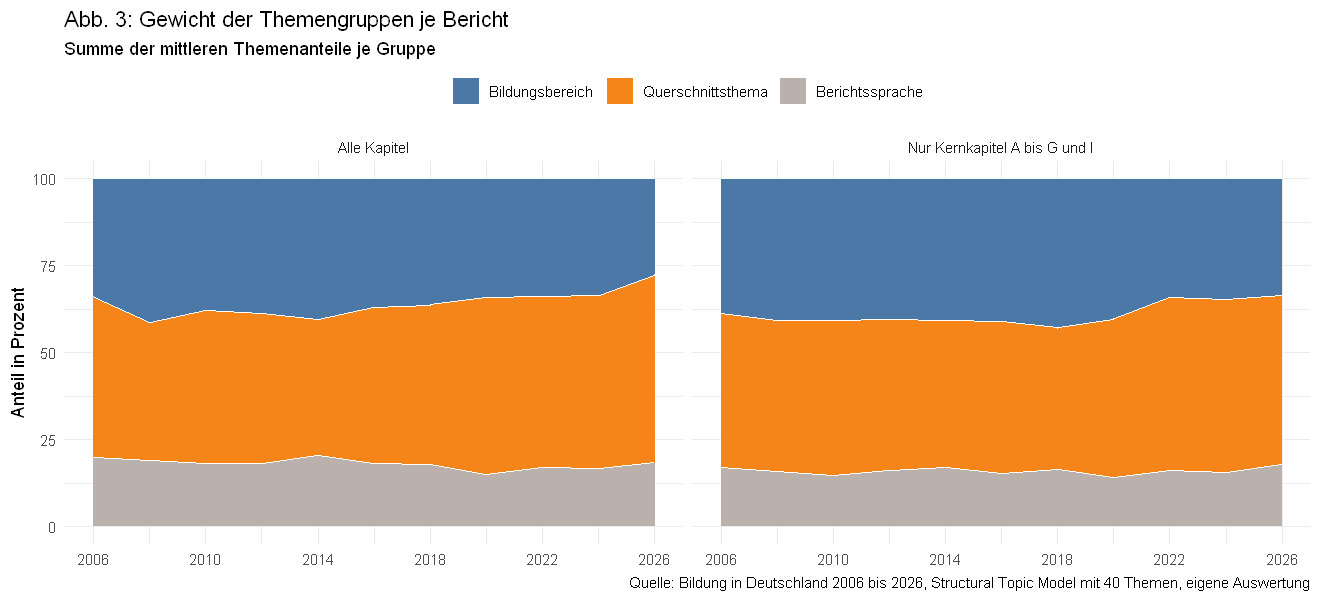

In [16]:
options(repr.plot.width = 11, repr.plot.height = 5)

farben_gruppen <- c("Bildungsbereich" = "#4c78a8", "Querschnittsthema" = "#f58518",
                    "Berichtssprache" = "#bab0ac")

gruppen <- bind_rows(
  lang |> mutate(basis = "Alle Kapitel"),
  lang |> filter(kapitelgruppe == "Kernkapitel") |> mutate(basis = "Nur Kernkapitel A bis G und I")
) |>
  group_by(basis, jahr, gruppe) |>
  summarise(anteil = 100 * sum(theta) / n_distinct(dok), .groups = "drop") |>
  mutate(gruppe = factor(gruppe, levels = names(farben_gruppen)))

abb3 <- ggplot(gruppen, aes(jahr, anteil, fill = gruppe)) +
  geom_area(colour = "white", linewidth = 0.3) +
  facet_wrap(~ basis) +
  scale_fill_manual(values = farben_gruppen, name = NULL) +
  scale_x_continuous(breaks = seq(2006, 2026, 4)) +
  labs(x = NULL, y = "Anteil in Prozent",
       title = "Abb. 3: Gewicht der Themengruppen je Bericht",
       subtitle = "Summe der mittleren Themenanteile je Gruppe",
       caption = quelle) +
  theme_minimal(base_size = 11) +
  theme(legend.position = "top")

ggsave("figures/abb3_themengruppen.png", abb3, width = 11, height = 5, dpi = 300)
abb3

print(gruppen |>
        mutate(anteil = round(anteil, 1)) |>
        pivot_wider(names_from = jahr, values_from = anteil), width = Inf)

Befund zu Abbildung 3. Über alle Kapitel wächst das Gewicht der Querschnittsthemen von rund 46 Prozent (2006) auf rund 54 Prozent (2026). Die Bildungsbereiche sinken von rund 34 auf rund 28 Prozent. Die Berichtssprache bleibt mit 15 bis 20 Prozent stabil.

Die Verschiebung zeigt sich auch in den Kernkapiteln: Dort liegen die Bildungsbereiche bis 2020 bei rund 39 bis 43 Prozent und ab 2022 bei rund 34 Prozent. Der Bericht behandelt also auch in den fortgeschriebenen Kapiteln seit 2022 mehr bereichsübergreifende Fragen. Die Schwerpunktkapitel verstärken diese Verschiebung, sie erzeugen sie nicht allein.

#### Abbildung 4: Ausgewählte Themen im Detail

Elf Themen zeigen vier Muster:

- Zunahme: Steuerung des Bildungssystems (T5), Programme und Qualitätssicherung (T33), frühe Bildung allgemein (T3)
- Schwerpunktspitzen: soziale Herkunft und Ungleichheit (T38), Lehrkräfte (T29)
- Abnahme: Bildungsstand der Bevölkerung (T23), internationaler Vergleich (T16), Schularten im Sekundarbereich (T7), Ausbildungsmarkt und Übergangssystem (T18)
- Ereignis: Corona-Pandemie (T21), Zuwanderung und Integration (T25)

Jedes Feld zeigt zwei Linien. Die blaue Linie beruht auf allen Kapiteln, die grüne nur auf den Kernkapiteln A bis G und I. Liegen beide Linien nah beieinander, trägt der Trend durch den ganzen Bericht. Steigt nur die blaue Linie, stammt der Anstieg aus dem Schwerpunktkapitel H oder dem Überblick.

Jedes Feld hat eine eigene Skala auf der y-Achse, damit auch kleine Themen sichtbar bleiben. Die Höhe der Kurven ist deshalb zwischen den Feldern nicht vergleichbar, nur ihr Verlauf.

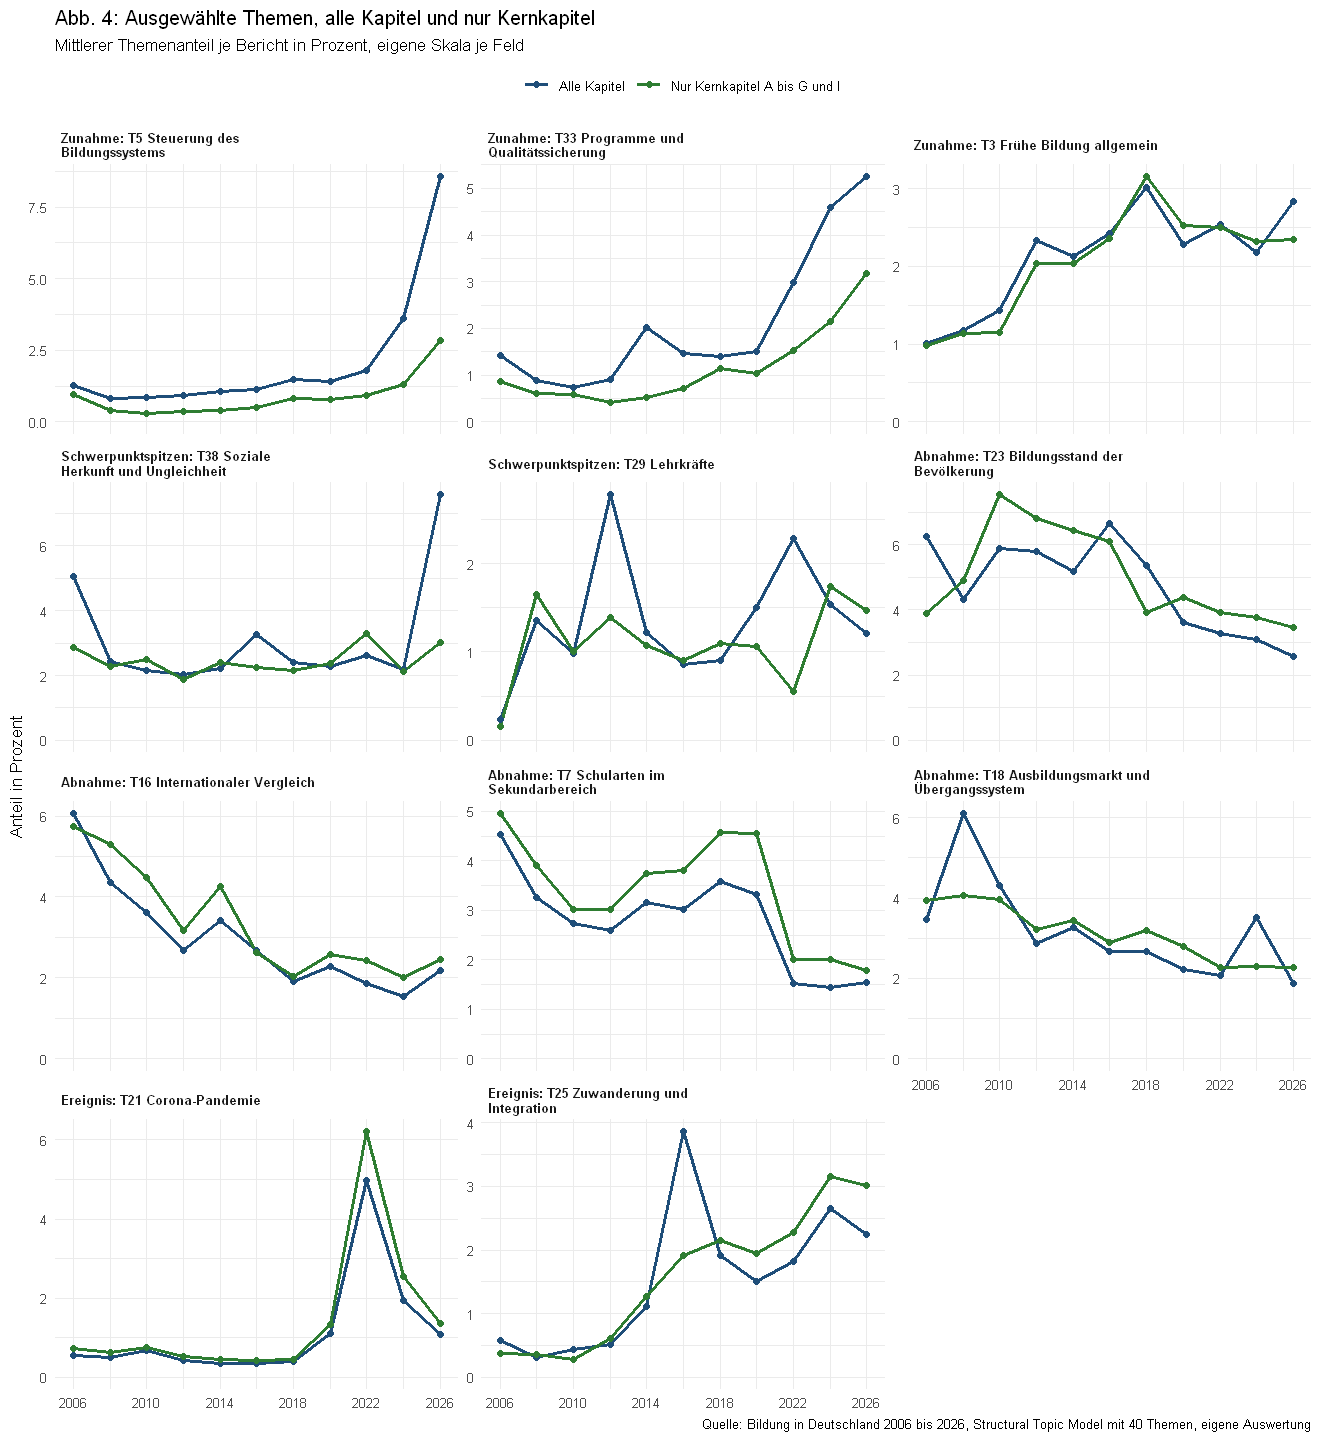

In [17]:
options(repr.plot.width = 11, repr.plot.height = 12)

auswahl <- tibble::tribble(
  ~thema, ~muster,
   5, "Zunahme", 33, "Zunahme",  3, "Zunahme",
  38, "Schwerpunktspitzen", 29, "Schwerpunktspitzen",
  23, "Abnahme", 16, "Abnahme",  7, "Abnahme", 18, "Abnahme",
  21, "Ereignis", 25, "Ereignis"
)

vergleich <- bind_rows(
  lang |> mutate(basis = "Alle Kapitel"),
  lang |> filter(kapitelgruppe == "Kernkapitel") |> mutate(basis = "Nur Kernkapitel A bis G und I")
) |>
  filter(thema %in% auswahl$thema) |>
  group_by(basis, thema, label, jahr) |>
  summarise(anteil = 100 * mean(theta), .groups = "drop") |>
  left_join(auswahl, by = "thema") |>
  mutate(feld = paste0(muster, ": ", label))

vergleich$feld <- factor(vergleich$feld,
                         levels = unique(vergleich$feld[order(match(vergleich$thema, auswahl$thema))]))

abb4 <- ggplot(vergleich, aes(jahr, anteil, colour = basis)) +
  geom_line(linewidth = 0.9) +
  geom_point(size = 1.6) +
  facet_wrap(~ feld, ncol = 3, scales = "free_y",
             labeller = label_wrap_gen(width = 40)) +
  scale_colour_manual(values = c("Alle Kapitel" = "#1f4e79",
                                 "Nur Kernkapitel A bis G und I" = "#2e7d32"), name = NULL) +
  scale_x_continuous(breaks = seq(2006, 2026, 4)) +
  expand_limits(y = 0) +
  labs(x = NULL, y = "Anteil in Prozent",
       title = "Abb. 4: Ausgewählte Themen, alle Kapitel und nur Kernkapitel",
       subtitle = "Mittlerer Themenanteil je Bericht in Prozent, eigene Skala je Feld",
       caption = quelle) +
  theme_minimal(base_size = 10) +
  theme(legend.position = "top", strip.text = element_text(face = "bold", hjust = 0))

ggsave("figures/abb4_ausgewaehlte_themen.png", abb4, width = 11, height = 12, dpi = 300)
abb4

Befund zu Abbildung 4. Der Vergleich der beiden Linien trennt dauerhafte Trends von Schwerpunkten.

- Programme und Qualitätssicherung (T33) steigt in den Kernkapiteln stetig, von rund 0,4 (2012) auf 3,2 Prozent (2026). Das ist der deutlichste dauerhafte Anstieg.
- Steuerung (T5) steigt auch in den Kernkapiteln, aber auf niedrigem Niveau (auf rund 2,8 Prozent 2026). Der Sprung auf 8,6 Prozent kommt aus Überblick und Schwerpunktkapitel.
- Frühe Bildung (T3) steigt in beiden Linien gleich bis 2018 und bleibt danach auf rund 2,5 Prozent.
- Soziale Herkunft (T38) liegt in den Kernkapiteln ohne Trend bei rund 2 bis 3,3 Prozent. Die Spitzen 2006 und 2026 entstehen nur in der blauen Linie.
- Lehrkräfte (T29) schwanken ohne Trend. Die Spitzen 2012 und 2022 entstehen nur in der blauen Linie.
- Bildungsstand der Bevölkerung (T23), internationaler Vergleich (T16) und Ausbildungsmarkt (T18) sinken in beiden Linien. Diese Rückgänge sind dauerhaft.
- Schularten im Sekundarbereich (T7) fallen in den Kernkapiteln 2022 abrupt von rund 4,5 auf 2,0 Prozent. Die Ursache ist offen, eine Umstellung von Kapitel D im Bericht 2022 ist möglich.
- Corona (T21) erreicht 2022 den Höchstwert in beiden Linien, in den Kernkapiteln sogar höher (6,2 Prozent).
- Zuwanderung (T25) zeigt zwei Muster zugleich: eine Spitze 2016, nur in der blauen Linie, und einen stetigen Anstieg in den Kernkapiteln von rund 0,4 auf 3,1 Prozent. Das Thema ist in die Fortschreibung eingegangen.

#### Abbildung 5: Aus welchen Kapiteln die Anstiege stammen

Für vier auffällige Themen zeigt jeder Balken den Anteil des Themas an einem Bericht, aufgeteilt nach Kapitelgruppe. Die Gesamthöhe eines Balkens entspricht dem Jahreswert in Abbildung 4 (blaue Linie).

So liest man die Abbildung: Ein hoher Balken mit großem grauem Anteil heißt, das Thema ist in den fortgeschriebenen Kapiteln präsent. Ein hoher Balken mit großem orangem oder blauem Anteil heißt, der Ausschlag geht auf das Schwerpunktkapitel H oder den Überblick zurück.

Die Auswahl:

- T5 Steuerung und T38 soziale Herkunft: die stärksten Anstiege 2026
- T33 Programme und Qualitätssicherung: Anstieg seit 2022
- T18 Ausbildungsmarkt: Spitzen 2008 und 2024

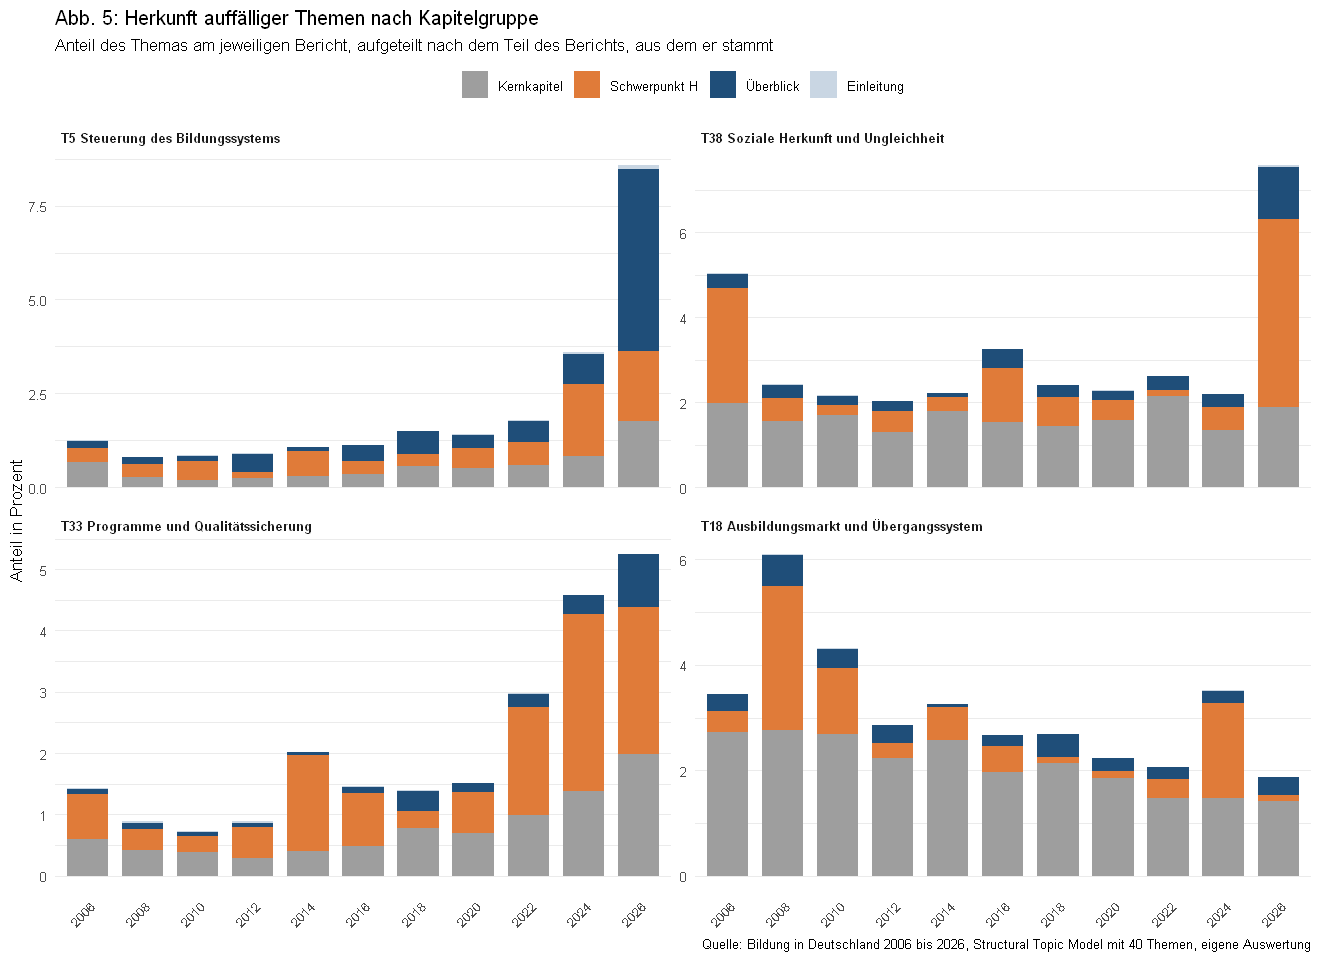

In [18]:
options(repr.plot.width = 11, repr.plot.height = 8)

herkunft <- lang |>
  filter(thema %in% c(5, 38, 33, 18)) |>
  group_by(thema, label, jahr, kapitelgruppe) |>
  summarise(summe = sum(theta), .groups = "drop") |>
  left_join(n_jahr, by = "jahr") |>
  mutate(anteil = 100 * summe / n_jahr,
         kapitelgruppe = factor(kapitelgruppe, levels = rev(names(farben_kapitel))))

herkunft$label <- factor(herkunft$label,
                         levels = unique(herkunft$label[order(match(herkunft$thema, c(5, 38, 33, 18)))]))

abb5 <- ggplot(herkunft, aes(factor(jahr), anteil, fill = kapitelgruppe)) +
  geom_col(width = 0.75) +
  facet_wrap(~ label, ncol = 2, scales = "free_y") +
  scale_fill_manual(values = farben_kapitel, name = NULL, breaks = names(farben_kapitel)) +
  labs(x = NULL, y = "Anteil in Prozent",
       title = "Abb. 5: Herkunft auffälliger Themen nach Kapitelgruppe",
       subtitle = "Anteil des Themas am jeweiligen Bericht, aufgeteilt nach dem Teil des Berichts, aus dem er stammt",
       caption = quelle) +
  theme_minimal(base_size = 10) +
  theme(legend.position = "top", panel.grid.major.x = element_blank(),
        axis.text.x = element_text(angle = 45, hjust = 1),
        strip.text = element_text(face = "bold", hjust = 0))

ggsave("figures/abb5_herkunft_kapitel.png", abb5, width = 11, height = 8, dpi = 300)
abb5

Befund zu Abbildung 5. Die Balken zeigen, aus welchem Teil des Berichts die Anstiege stammen.

- Steuerung (T5): 2026 stammen rund 4,9 der 8,6 Prozentpunkte aus dem Überblick, rund 1,9 aus dem Schwerpunktkapitel und rund 1,8 aus den Kernkapiteln. Der Anstieg ist vor allem eine Folge der "Zentralen Herausforderungen" im Überblick 2026.
- Soziale Herkunft (T38): Die Spitzen 2006 und 2026 kommen aus dem Schwerpunktkapitel (2026 rund 4,4 Prozentpunkte). Der Anteil der Kernkapitel bleibt über 20 Jahre bei rund 1,3 bis 2,2.
- Programme und Qualitätssicherung (T33): Das Schwerpunktkapitel trägt 2014 und von 2022 bis 2026 viel bei. Der Anteil der Kernkapitel wächst unabhängig davon, von rund 0,3 (2012) auf 2,0 (2026).
- Ausbildungsmarkt (T18): Die Spitzen 2008 und 2024 stammen aus dem Schwerpunktkapitel. In den Kernkapiteln sinkt der Anteil von rund 2,7 auf 1,4.

#### Folgerung für die weitere Analyse

Die Abbildungen zeigen zwei Schichten der Themenentwicklung:

1. Dauerhafte Verschiebungen in den Kernkapiteln A bis G und I. Sie beantworten die Frage, welche Themen über 20 Jahre konstant bleiben, hinzukommen oder zurückgehen.
2. Spitzen im Schwerpunktkapitel H und im Überblick. Sie zeigen, welche Themen ein Bericht einmalig in den Mittelpunkt stellt.

Die weitere Trendanalyse rechne ich deshalb auf den Kernkapiteln. Schwerpunktkapitel und Überblick werte ich getrennt aus. Der Überblick verdient eine eigene Auswertung, weil er 2026 erstmals "Zentrale Herausforderungen" benennt. Er ist damit die naheliegende Textgrundlage für die Frage nach wiederkehrenden Herausforderungen.

### 13. Konstante, neue und zurückgehende Themen in den Kernkapiteln

Diese Auswertung beantwortet Forschungsfrage 1. Grundlage sind nur die Kernkapitel A bis G und I, weil das Schwerpunktkapitel H und der Überblick die Jahresmittel verzerren (Abschnitt 12).

Ich vergleiche die drei ersten Berichte (2006, 2008, 2010) mit den drei letzten (2022, 2024, 2026) und ordne jedes inhaltliche Thema einem von fünf Mustern zu:

| Muster | Regel |
|---|---|
| kommt hinzu | Anteil spät mindestens 1,5-mal so hoch wie früh, und jeder späte Bericht liegt über jedem frühen |
| geht zurück | Anteil spät höchstens zwei Drittel des frühen, und jeder späte Bericht liegt unter jedem frühen |
| leichte Verschiebung | alle späten Berichte liegen über oder unter allen frühen, die Veränderung erreicht aber nicht den Faktor 1,5 |
| konstant | kein stetiger Trend, und der Anteil ändert sich höchstens um den Faktor 1,25 (0,8 bis 1,25) |
| uneinheitlich | kein stetiger Trend, aber der Anteil ändert sich stärker |

Die Bedingung "jeder späte Bericht liegt über jedem frühen" stellt sicher, dass ein einzelner Bericht das Ergebnis nicht bestimmt. Die Schwellen 1,5 und 1,25 lege ich selbst fest. Ein Signifikanztest ist hier nicht sinnvoll: Es gibt nur elf Berichte, und die Absätze eines Berichts sind nicht unabhängig voneinander.

Die Gruppen "konstant" und "uneinheitlich" habe ich nach einem ersten Durchlauf getrennt. Dort bildeten sie eine gemeinsame Restgruppe, und Abbildung 6 zeigte, dass diese Gruppe Themen ohne Veränderung mit Themen mit starker, aber ungleichmäßiger Veränderung mischt.

In [19]:
spalten <- paste0("T", 1:40)
kern <- beobachtet |> filter(!kapitel %in% c("H", "UEB", "EIN"))

jahr_mittel <- kern |>
  group_by(jahr) |>
  summarise(across(all_of(spalten), \(x) 100 * mean(x)), .groups = "drop")
jahre_frueh <- jahr_mittel |> filter(jahr <= 2010)
jahre_spaet <- jahr_mittel |> filter(jahr >= 2022)

muster_k40 <- tibble(
  thema = 1:40,
  frueh = sapply(spalten, \(s) mean(jahre_frueh[[s]])),
  spaet = sapply(spalten, \(s) mean(jahre_spaet[[s]])),
  stetig_hoeher = sapply(spalten, \(s) min(jahre_spaet[[s]]) > max(jahre_frueh[[s]])),
  stetig_tiefer = sapply(spalten, \(s) max(jahre_spaet[[s]]) < min(jahre_frueh[[s]]))
) |>
  mutate(
    faktor = spaet / frueh,
        muster = case_when(
      faktor >= 1.5 & stetig_hoeher ~ "kommt hinzu",
      faktor <= 2/3 & stetig_tiefer ~ "geht zurück",
      stetig_hoeher | stetig_tiefer ~ "leichte Verschiebung",
      faktor >= 0.8 & faktor <= 1.25 ~ "konstant",
      TRUE ~ "uneinheitlich"
    )
  ) |>
  left_join(themen_namen |> select(thema, kurzname, gruppe), by = "thema") |>
  filter(gruppe != "Berichtssprache") |>
  mutate(across(c(frueh, spaet, faktor), \(x) round(x, 2))) |>
  arrange(desc(faktor))

write.csv(muster_k40, "data/processed/stm_k40_muster_kernkapitel.csv",
          row.names = FALSE, fileEncoding = "UTF-8")

print(count(muster_k40, muster))
print(muster_k40 |> select(thema, kurzname, frueh, spaet, faktor, muster), n = 32, width = Inf)

# Jahreswerte zur Kontrolle, gleiche Reihenfolge wie oben
cat("\nJahreswerte in den Kernkapiteln (Prozent):\n")
kontrolle <- jahr_mittel |>
  pivot_longer(-jahr, names_to = "thema", values_to = "anteil") |>
  mutate(thema = as.integer(sub("T", "", thema)), anteil = round(anteil, 1)) |>
  filter(thema %in% muster_k40$thema) |>
  pivot_wider(names_from = jahr, values_from = anteil)
print(kontrolle[match(muster_k40$thema, kontrolle$thema), ], n = 32, width = Inf)

# A tibble: 5 × 2
  muster                   n
  <chr>                <int>
1 geht zurück              8
2 kommt hinzu              8
3 konstant                 7
4 leichte Verschiebung     4
5 uneinheitlich            5
# A tibble: 32 × 6
   thema kurzname                                   frueh spaet faktor
   <dbl> <chr>                                      <dbl> <dbl>  <dbl>
 1    25 Zuwanderung und Integration                 0.33  2.81   8.43
 2    21 Corona-Pandemie                             0.7   3.38   4.85
 3    20 Digitalisierung                             0.35  1.48   4.25
 4    33 Programme und Qualitätssicherung            0.68  2.28   3.35
 5     5 Steuerung des Bildungssystems               0.55  1.69   3.07
 6    26 Junge Erwachsene und Engagement             1.74  4.12   2.37
 7    14 Familie und soziale Risikolagen             2.46  5.5    2.24
 8     3 Frühe Bildung allgemein                     1.09  2.39   2.19
 9    17 Hochschulen und Studienangebot           

#### Abbildung 6: Themen nach Muster

Jede Zeile zeigt ein Thema. Der graue Punkt ist der mittlere Anteil in den Berichten 2006 bis 2010, der farbige Punkt der in den Berichten 2022 bis 2026. Die Linie dazwischen zeigt Richtung und Größe der Veränderung. Die fünf Felder entsprechen den fünf Mustern. Innerhalb jedes Felds stehen die Themen nach dem Faktor der Veränderung sortiert.

Grundlage sind nur die Kernkapitel A bis G und I.

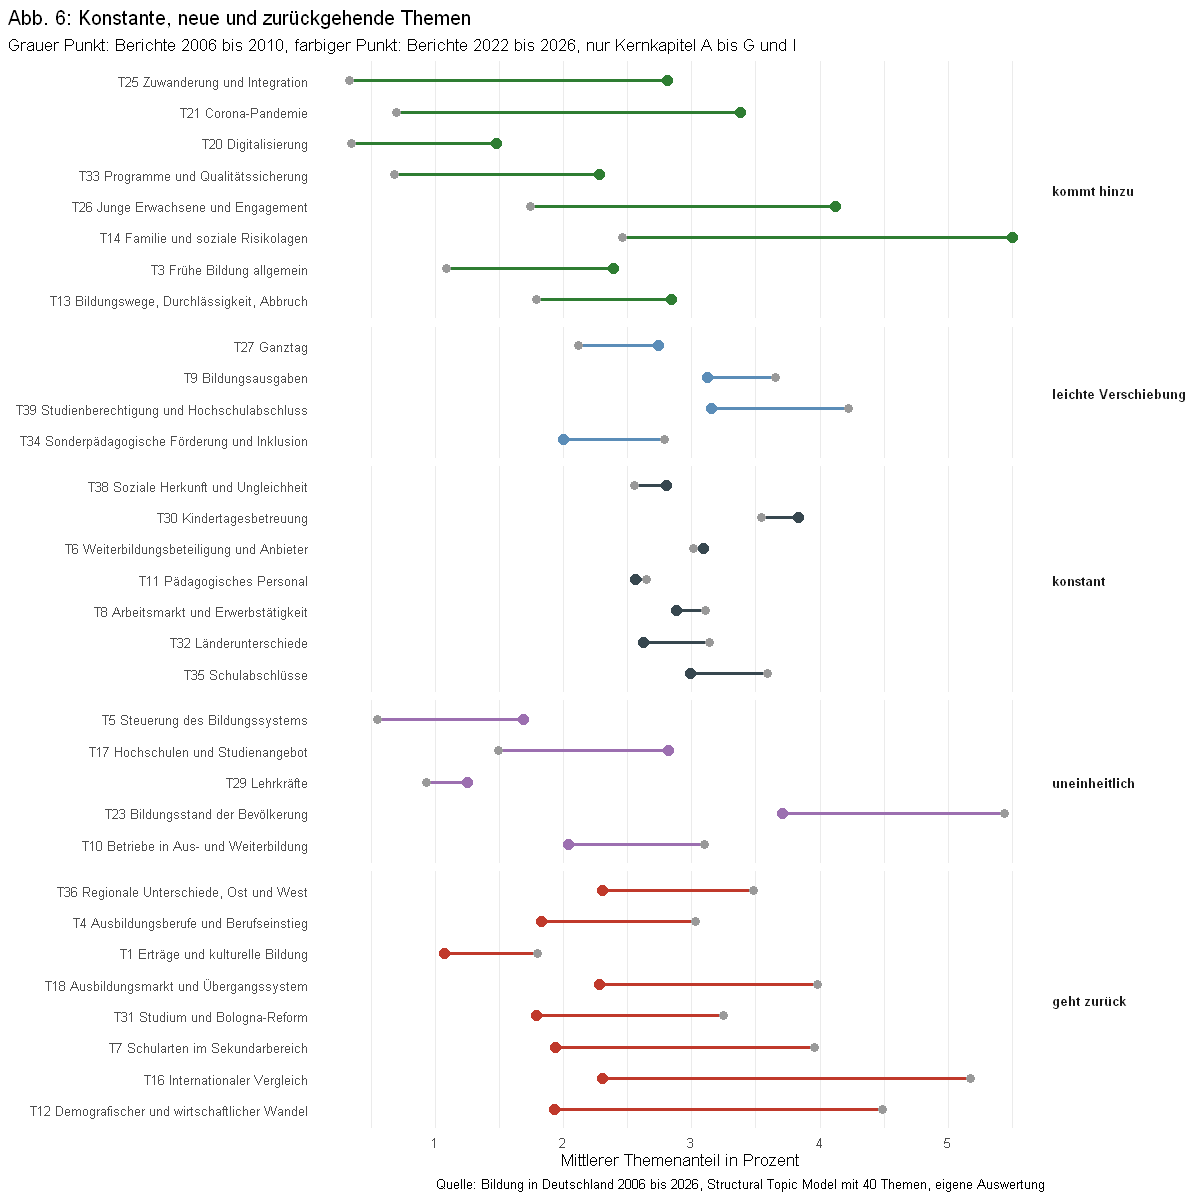

In [20]:
options(repr.plot.width = 10, repr.plot.height = 10)

stufen <- c("kommt hinzu", "leichte Verschiebung", "konstant", "uneinheitlich", "geht zurück")
farben_muster <- c("kommt hinzu" = "#2e7d32", "leichte Verschiebung" = "#5b8db8",
                   "konstant" = "#37474f", "uneinheitlich" = "#9c6fb0",
                   "geht zurück" = "#c0392b")

abb6_daten <- muster_k40 |>
  mutate(muster = factor(muster, levels = stufen),
         label = paste0("T", thema, " ", kurzname)) |>
  arrange(muster, faktor)
abb6_daten$label <- factor(abb6_daten$label, levels = abb6_daten$label)

abb6 <- ggplot(abb6_daten, aes(y = label)) +
  geom_segment(aes(x = frueh, xend = spaet, yend = label, colour = muster), linewidth = 1) +
  geom_point(aes(x = frueh), colour = "grey60", size = 2.2) +
  geom_point(aes(x = spaet, colour = muster), size = 2.8) +
  facet_grid(muster ~ ., scales = "free_y", space = "free_y") +
  scale_colour_manual(values = farben_muster, guide = "none") +
  labs(x = "Mittlerer Themenanteil in Prozent", y = NULL,
       title = "Abb. 6: Konstante, neue und zurückgehende Themen",
       subtitle = "Grauer Punkt: Berichte 2006 bis 2010, farbiger Punkt: Berichte 2022 bis 2026, nur Kernkapitel A bis G und I",
       caption = quelle) +
  theme_minimal(base_size = 10) +
  theme(plot.title.position = "plot",
        strip.text.y = element_text(angle = 0, face = "bold", hjust = 0),
        panel.grid.major.y = element_blank())

ggsave("figures/abb6_muster_kernkapitel.png", abb6, width = 10, height = 10, dpi = 300)
abb6

**Befund zu Abschnitt 13.** Von 32 inhaltlichen Themen kommen in den Kernkapiteln 8 hinzu, 8 gehen zurück, 4 verschieben sich leicht, 7 bleiben konstant und 5 verändern sich uneinheitlich.

Hinzu kommen (Anteil 2006 bis 2010 zu 2022 bis 2026, in Prozent):

- Zuwanderung und Integration (0,3 zu 2,8)
- Familie und soziale Risikolagen (2,5 zu 5,5)
- Junge Erwachsene und Engagement (1,7 zu 4,1)
- Programme und Qualitätssicherung (0,7 zu 2,3)
- Frühe Bildung allgemein (1,1 zu 2,4)
- Digitalisierung (0,4 zu 1,5)
- Bildungswege, Durchlässigkeit, Abbruch (1,8 zu 2,8)
- Corona-Pandemie (0,7 zu 3,4). Sie erfüllt die Regel, ist aber ein Ereignis mit Höchstwert 2022 (6,2) und Rückgang auf 1,4 im Jahr 2026.

Zurück gehen:

- Demografischer und wirtschaftlicher Wandel (4,5 zu 1,9)
- Internationaler Vergleich (5,2 zu 2,3)
- Schularten im Sekundarbereich (4,0 zu 1,9)
- Studium und Bologna-Reform (3,3 zu 1,8)
- Ausbildungsmarkt und Übergangssystem (4,0 zu 2,3)
- Ausbildungsberufe und Berufseinstieg (3,0 zu 1,8)
- Regionale Unterschiede, Ost und West (3,5 zu 2,3)
- Erträge und kulturelle Bildung (1,8 zu 1,1)

Leicht verschieben sich Ganztag (aufwärts) sowie Bildungsausgaben, Studienberechtigung und Hochschulabschluss und sonderpädagogische Förderung (abwärts).

Konstant bleiben soziale Herkunft und Ungleichheit (2,6 zu 2,8), Kindertagesbetreuung (3,5 zu 3,8), Weiterbildungsbeteiligung (3,0 zu 3,1), pädagogisches Personal (2,7 zu 2,6), Arbeitsmarkt (3,1 zu 2,9), Länderunterschiede (3,1 zu 2,6) und Schulabschlüsse (3,6 zu 3,0).

Uneinheitlich verändern sich:

- Steuerung des Bildungssystems (0,6 zu 1,7): 2006 liegt mit 1,0 über 2022 mit 0,9, der Anstieg beginnt erst 2024.
- Hochschulen und Studienangebot (1,5 zu 2,8): Die Werte schwanken zwischen 1,0 und 3,7.
- Lehrkräfte (0,9 zu 1,3): niedriges Niveau mit einzelnen Spitzen.
- Bildungsstand der Bevölkerung (5,4 zu 3,7): Höchstwert 2010 mit 7,5, danach Rückgang. Für "geht zurück" fehlen zwei Bedingungen knapp: Der Faktor liegt mit 0,68 über zwei Dritteln, und 2022 liegt mit 3,9 gleichauf mit 2006.
- Betriebe in Aus- und Weiterbildung (3,1 zu 2,0): Höchstwert 2010 mit 4,0, Tiefstwert 2016 mit 0,6.

Inhaltlich zeigt sich eine Verschiebung: Die neuen Themen beschreiben Lebenslagen (Familie, Zuwanderung, junge Erwachsene) und Steuerungsfragen (Programme, Qualitätssicherung). Die zurückgehenden Themen beschreiben Strukturen (Schularten, Bologna-Reform, Ausbildungsmarkt) und Rahmenbedingungen (Demografie, internationaler Vergleich). Soziale Herkunft bleibt in den Kernkapiteln über 20 Jahre auf gleichem Niveau.

Drei Rückgänge passieren als Sprung zwischen zwei Berichten: Ausbildungsberufe 2018 (4,8 zu 1,6), Schularten 2022 (4,6 zu 2,0) und Erträge 2018 (0,3, weil 2018 das Kapitel I fehlt). Solche Sprünge können auf eine geänderte Gliederung oder neue Indikatoren zurückgehen statt auf einen allmählichen Bedeutungsverlust. Das prüfe ich an den Indikatorenlisten der Berichte.

### 14. Robustheit: Muster bei 30 und 60 Themen

Die Kennzahlen in Abschnitt 5 trennen nicht eindeutig zwischen 30, 40 und 60 Themen. Ich prüfe deshalb, ob die Muster aus Abschnitt 13 auch in Modellen mit 30 und 60 Themen auftreten. Halten sie, hängen sie nicht an der gewählten Themenzahl.

Das Testmodell mit 30 Themen aus Abschnitt 2 ist nach 100 Iterationen nicht konvergiert. Ich schätze es hier neu, mit denselben Einstellungen wie die Kandidaten in Abschnitt 6 (bis zu 500 Iterationen). Das Modell mit 60 Themen aus Abschnitt 6 ist konvergiert und wird geladen.

Die neue Schätzung speichere ich unter `data/interim/stm_k30_final.rds`. Liegt die Datei schon vor, lädt die Zelle sie, statt neu zu schätzen.

Die erste Code-Zelle lädt alle benötigten Daten aus den gespeicherten Dateien. Der Abschnitt läuft deshalb auch für sich allein, ohne dass die Abschnitte 1 bis 13 vorher in derselben Sitzung laufen müssen.

In [21]:
setwd("C:/Users/c.sezgin/OneDrive - DIPF/Computational Social Sciences/bildungsbericht")
.libPaths(c(Sys.getenv("R_LIBS_USER"), .libPaths()))
suppressPackageStartupMessages({
  library(stm)
  library(dplyr)
  library(tidyr)
})

# Gespeicherte Ergebnisse laden, damit der Abschnitt auch nach einem Neustart läuft
stm_daten <- readRDS("data/interim/stm_daten.rds")
modell_k40 <- readRDS("data/interim/stm_k40.rds")
modell_k60 <- readRDS("data/interim/stm_k60.rds")
muster_k40 <- read.csv("data/processed/stm_k40_muster_kernkapitel.csv", fileEncoding = "UTF-8")
stufen <- c("kommt hinzu", "leichte Verschiebung", "konstant", "uneinheitlich", "geht zurück")

meta <- stm_daten$meta
meta$kapitel <- factor(meta$kapitel,
                       levels = c("A", "EIN", "UEB", "B", "C", "D", "E", "F", "G", "H", "I"))

datei_k30 <- "data/interim/stm_k30_final.rds"
if (file.exists(datei_k30)) {
  modell_k30 <- readRDS(datei_k30)
} else {
  zeit <- system.time(
    modell_k30 <- stm(
      documents = stm_daten$documents,
      vocab = stm_daten$vocab,
      K = 30,
      prevalence = ~ kapitel + s(jahr, df = 5),
      data = meta,
      init.type = "Spectral",
      max.em.its = 500,
      seed = 2026,
      verbose = FALSE
    )
  )
  saveRDS(modell_k30, datei_k30)
  cat("Laufzeit:", round(zeit[["elapsed"]] / 60, 1), "Minuten\n")
}

cat("K = 30:", length(modell_k30$convergence$bound), "Iterationen, konvergiert:",
    modell_k30$convergence$converged, "\n")
cat("K = 60:", length(modell_k60$convergence$bound), "Iterationen, konvergiert:",
    modell_k60$convergence$converged, "\n")
cat("Muster aus Abschnitt 13:", nrow(muster_k40), "Themen\n")

K = 30: 117 Iterationen, konvergiert: TRUE 
K = 60: 107 Iterationen, konvergiert: TRUE 
Muster aus Abschnitt 13: 32 Themen


#### Prüfung der gespeicherten Modelle

Die Modelle mit 40 und 60 Themen wurden vor dem letzten Lauf von `01_vorverarbeitung.ipynb` geschätzt, der `stm_daten.rds` neu geschrieben hat. Ich prüfe deshalb, ob jedes Modell zur aktuellen Dokument-Wort-Matrix passt: gleiches Vokabular, gleiche Zahl der Dokumente und gleiche Häufigkeit jedes Worts. Stimmen alle drei Merkmale, wurde das Modell mit derselben Matrix geschätzt.

Das Ergebnis gilt auch für die Abschnitte 8 bis 13, die das Modell mit 40 Themen zusammen mit derselben Matrix nutzen.

In [22]:
# Prüfung: Wurden die gespeicherten Modelle mit genau dieser Dokument-Wort-Matrix geschätzt?
woerter_daten <- numeric(length(stm_daten$vocab))
for (d in stm_daten$documents) {
  woerter_daten[d[1, ]] <- woerter_daten[d[1, ]] + d[2, ]
}

pruefe <- function(modell, name) {
  cat(sprintf("%s: Vokabular gleich: %s | Dokumente gleich: %s | Worthäufigkeiten gleich: %s\n",
              name,
              identical(modell$vocab, stm_daten$vocab),
              nrow(modell$theta) == length(stm_daten$documents),
              isTRUE(all.equal(as.numeric(modell$settings$dim$wcounts$x), woerter_daten))))
}
pruefe(modell_k30, "K = 30")
pruefe(modell_k40, "K = 40")
pruefe(modell_k60, "K = 60")

K = 30: Vokabular gleich: TRUE | Dokumente gleich: TRUE | Worthäufigkeiten gleich: TRUE
K = 40: Vokabular gleich: TRUE | Dokumente gleich: TRUE | Worthäufigkeiten gleich: TRUE
K = 60: Vokabular gleich: TRUE | Dokumente gleich: TRUE | Worthäufigkeiten gleich: TRUE


**Ergebnis der Prüfung.** Alle drei Modelle stimmen in Vokabular (4.241 Wörter), Zahl der Dokumente (9.125) und Häufigkeit jedes Worts mit der aktuellen Matrix überein. Die gespeicherten Modelle passen damit zu `stm_daten.rds`, und die Ergebnisse der Abschnitte 8 bis 14 beruhen auf derselben Datengrundlage.

#### Zuordnung der Themen und Vergleich der Muster

Die Themen der Vergleichsmodelle tragen andere Nummern und schneiden das Material anders zu. Ich ordne sie über ihre Wortverteilung zu:

1. Für jedes Thema eines Vergleichsmodells berechne ich die Kosinus-Ähnlichkeit seiner Wortverteilung mit allen 40 Themen des Hauptmodells. Der Wert liegt zwischen 0 (keine gemeinsamen Wörter) und 1 (gleiche Verteilung).
2. Jedes Vergleichsthema ordne ich dem ähnlichsten Thema des Hauptmodells zu.
3. Fallen mehrere Vergleichsthemen auf dasselbe Hauptthema, addiere ich ihre Anteile. So bleibt ein Thema vergleichbar, das bei 60 Themen in Unterthemen zerfällt.
4. Auf die addierten Anteile in den Kernkapiteln wende ich dieselben Regeln an wie in Abschnitt 13.

Erhält ein Hauptthema keine Zuordnung, ist es im Vergleichsmodell mit einem anderen Thema verschmolzen. Ich weise es als "keine Entsprechung" aus.

Zur Kontrolle wende ich das Verfahren zuerst auf das Hauptmodell selbst an. Es muss die Muster aus Abschnitt 13 genau wiedergeben.

In [23]:
# Regeln aus Abschnitt 13 für einen einzelnen Themenverlauf
muster_regel <- function(frueh_jahre, spaet_jahre) {
  faktor <- mean(spaet_jahre) / mean(frueh_jahre)
  hoeher <- min(spaet_jahre) > max(frueh_jahre)
  tiefer <- max(spaet_jahre) < min(frueh_jahre)
  if (faktor >= 1.5 && hoeher) {
    "kommt hinzu"
  } else if (faktor <= 2/3 && tiefer) {
    "geht zurück"
  } else if (hoeher || tiefer) {
    "leichte Verschiebung"
  } else if (faktor >= 0.8 && faktor <= 1.25) {
    "konstant"
  } else {
    "uneinheitlich"
  }
}

# Grobe Richtung: steigt, sinkt oder bleibt gleich (Faktor 0,8 bis 1,25)
richtung <- function(faktor) {
  case_when(is.na(faktor) ~ "keine Entsprechung",
            faktor > 1.25 ~ "steigt",
            faktor < 0.8 ~ "sinkt",
            TRUE ~ "gleich")
}

kosinus <- function(a, b) {
  a <- a / sqrt(rowSums(a^2))
  b <- b / sqrt(rowSums(b^2))
  a %*% t(b)
}

beta_k40 <- exp(modell_k40$beta$logbeta[[1]])
ist_kern <- !stm_daten$meta$kapitel %in% c("H", "UEB", "EIN")
jahr_kern <- stm_daten$meta$jahr[ist_kern]
themen_inhalt <- muster_k40$thema

vergleich_modell <- function(modell) {
  k <- ncol(modell$theta)
  sim <- kosinus(exp(modell$beta$logbeta[[1]]), beta_k40)
  zuordnung <- tibble(thema_alt = 1:k,
                      thema = apply(sim, 1, which.max),
                      aehnlichkeit = apply(sim, 1, max))
  bind_rows(lapply(themen_inhalt, function(t) {
    alt <- zuordnung$thema_alt[zuordnung$thema == t]
    if (length(alt) == 0) {
      return(tibble(thema = t, k = k, muster_alt = "keine Entsprechung",
                    faktor_alt = NA_real_, aehnlichkeit = NA_real_, anzahl = 0L))
    }
    anteil <- rowSums(modell$theta[ist_kern, alt, drop = FALSE])
    jm <- 100 * tapply(anteil, jahr_kern, mean)
    frueh <- jm[c("2006", "2008", "2010")]
    spaet <- jm[c("2022", "2024", "2026")]
    tibble(thema = t, k = k,
           muster_alt = muster_regel(frueh, spaet),
           faktor_alt = round(mean(spaet) / mean(frueh), 2),
           aehnlichkeit = round(max(zuordnung$aehnlichkeit[zuordnung$thema == t]), 2),
           anzahl = length(alt))
  }))
}

# Kontrolle: Das Hauptmodell muss sich selbst genau wiedergeben
kontrolle_k40 <- vergleich_modell(modell_k40) |>
  left_join(muster_k40 |> select(thema, muster), by = "thema")
cat("Kontrolle K = 40, übereinstimmende Muster:",
    sum(kontrolle_k40$muster_alt == kontrolle_k40$muster), "von", nrow(kontrolle_k40), "\n\n")

robust <- bind_rows(vergleich_modell(modell_k30), vergleich_modell(modell_k60)) |>
  pivot_wider(names_from = k, values_from = c(muster_alt, faktor_alt, aehnlichkeit, anzahl))

robust <- as_tibble(muster_k40) |>
  select(thema, kurzname, muster, faktor) |>
  left_join(robust, by = "thema") |>
  mutate(gleich_30 = muster == muster_alt_30,
         gleich_60 = muster == muster_alt_60,
         richtung_40 = richtung(faktor),
         richtung_30 = richtung(faktor_alt_30),
         richtung_60 = richtung(faktor_alt_60),
         muster = factor(muster, levels = stufen)) |>
  arrange(muster, desc(faktor))

write.csv(robust, "data/processed/stm_robustheit_muster.csv",
          row.names = FALSE, fileEncoding = "UTF-8")

cat("Gleiches Muster bei 30 Themen:", sum(robust$gleich_30), "von", nrow(robust), "\n")
cat("Gleiches Muster bei 60 Themen:", sum(robust$gleich_60), "von", nrow(robust), "\n")
cat("Gleiche Richtung bei 30 Themen:", sum(robust$richtung_40 == robust$richtung_30), "von", nrow(robust), "\n")
cat("Gleiche Richtung bei 60 Themen:", sum(robust$richtung_40 == robust$richtung_60), "von", nrow(robust), "\n")
cat("Gleiche Richtung in beiden:",
    sum(robust$richtung_40 == robust$richtung_30 & robust$richtung_40 == robust$richtung_60),
    "von", nrow(robust), "\n\n")

print(robust |>
        select(thema, kurzname, muster, faktor,
               muster_alt_30, faktor_alt_30, aehnlichkeit_30, anzahl_30,
               muster_alt_60, faktor_alt_60, aehnlichkeit_60, anzahl_60),
      n = 32, width = Inf)

Kontrolle K = 40, übereinstimmende Muster: 32 von 32 

Gleiches Muster bei 30 Themen: 11 von 32 
Gleiches Muster bei 60 Themen: 15 von 32 
Gleiche Richtung bei 30 Themen: 15 von 32 
Gleiche Richtung bei 60 Themen: 22 von 32 
Gleiche Richtung in beiden: 12 von 32 

# A tibble: 32 × 12
   thema kurzname                                   muster               faktor
   <int> <chr>                                      <fct>                 <dbl>
 1    25 Zuwanderung und Integration                kommt hinzu            8.43
 2    21 Corona-Pandemie                            kommt hinzu            4.85
 3    20 Digitalisierung                            kommt hinzu            4.25
 4    33 Programme und Qualitätssicherung           kommt hinzu            3.35
 5    26 Junge Erwachsene und Engagement            kommt hinzu            2.37
 6    14 Familie und soziale Risikolagen            kommt hinzu            2.24
 7     3 Frühe Bildung allgemein                    kommt hinzu            

**Befund zu Abschnitt 14.** Die Kontrolle bestätigt das Verfahren: Angewendet auf das Hauptmodell gibt es alle 32 Muster aus Abschnitt 13 wieder.

| Vergleich | 30 Themen | 60 Themen |
|---|---|---|
| Themen mit Entsprechung | 24 von 32 | 32 von 32 |
| gleiches Muster (fünf Gruppen) | 11 von 32 | 15 von 32 |
| gleiche Richtung (steigt, sinkt, gleich) | 15 von 32 (15 von 24 mit Entsprechung) | 22 von 32 |

Der Vergleich nach fünf Mustern ist streng: Rutscht ein Thema von "kommt hinzu" zu "leichte Verschiebung", zählt das als Abweichung, obwohl die Richtung gleich bleibt. Aussagekräftiger ist deshalb der Vergleich der Richtung.

Drei Gründe erklären einen Teil der Abweichungen:

- Bei 30 Themen verschmelzen 8 Themen mit anderen, darunter Zuwanderung, frühe Bildung und Schularten. Für sie gibt es keinen Vergleich.
- Einige Zuordnungen sind schwach (Ähnlichkeit unter 0,7). Im Modell mit 30 Themen betrifft das Kindertagesbetreuung (0,2, das zugeordnete Thema ist also ein anderes), Programme und Qualitätssicherung, Bildungswege, Steuerung und Ausbildungsberufe. Im Modell mit 60 Themen betrifft es Bildungsstand der Bevölkerung (0,58), Studienberechtigung, Bologna-Reform, Steuerung, Arbeitsmarkt und junge Erwachsene.
- Länderunterschiede (Faktor 0,84) und Schulabschlüsse (0,83) liegen nahe an der Schwelle 0,8. Kleine Unterschiede zwischen den Modellen ändern dort die Einordnung.

Belastbar sind die Befunde, deren Richtung in allen vergleichbaren Modellen gleich bleibt:

- Es steigen Digitalisierung, Programme und Qualitätssicherung, Familie und soziale Risikolagen, Corona-Pandemie, Zuwanderung und Integration, frühe Bildung, Ganztag und Lehrkräfte.
- Es sinken internationaler Vergleich, Ausbildungsberufe und Berufseinstieg, Erträge und kulturelle Bildung, Betriebe in Aus- und Weiterbildung, Schularten im Sekundarbereich, demografischer Wandel, regionale Unterschiede sowie Studienberechtigung und Hochschulabschluss.
- Auf gleichem Niveau (Faktor 0,8 bis 1,25) bleiben Bildungsausgaben und pädagogisches Personal.

Vom Modell abhängig sind 14 Themen:

- Sie steigen nur im Hauptmodell: Steuerung des Bildungssystems (bei 30 und 60 Themen gleich), Bildungswege, Durchlässigkeit, Abbruch (bei 30 und 60 Themen gleich), junge Erwachsene und Engagement (bei 60 Themen gleich) sowie Hochschulen und Studienangebot (bei 30 Themen gleich).
- Sie sinken nur im Hauptmodell: Bildungsstand der Bevölkerung (bei 30 Themen gleich, bei 60 Themen steigend, dort mit schwacher Zuordnung), Studium und Bologna-Reform (bei 60 Themen gleich), sonderpädagogische Förderung (bei 60 Themen gleich) sowie Ausbildungsmarkt und Übergangssystem (bei 30 Themen steigend).
- Sie bleiben im Hauptmodell gleich, aber nicht in den Vergleichsmodellen: soziale Herkunft und Ungleichheit (bei 60 Themen gleich, Faktor 0,94, bei 30 Themen steigend, 1,43, dort mit einem zweiten Thema verschmolzen), Kindertagesbetreuung (bei 60 Themen gleich, bei 30 Themen ohne verlässliche Zuordnung), Weiterbildungsbeteiligung (bei 60 Themen steigend), Arbeitsmarkt (bei 30 und 60 Themen sinkend), Länderunterschiede (bei 30 und 60 Themen sinkend) und Schulabschlüsse (bei 60 Themen sinkend).

Für Steuerung heißt das: Der starke Anstieg in den Abschnitten 10 und 11 stammt aus dem Überblick und dem Schwerpunktkapitel. Einen Anstieg in den Kernkapiteln bestätigen die Vergleichsmodelle nicht.

Für die Deutung von Forschungsfrage 1 stütze ich mich auf die belastbaren Befunde. Die modellabhängigen Themen weise ich als unsicher aus.

## Zusammenfassung

### Ziel

Dieses Notebook schätzt ein Structural Topic Model auf den elf Bildungsberichten 2006 bis 2026 und beantwortet Forschungsfrage 1: Welche Themen bleiben über 20 Jahre konstant, welche kommen hinzu, welche gehen zurück?

### Entscheidungen und Gründe

| Schritt | Entscheidung | Grund |
|---|---|---|
| Modellformel | `~ kapitel + s(jahr, df = 5)`, spektrale Startwerte | Kapitel rechnet die feste Gliederung heraus, der Spline erlaubt nicht lineare Verläufe, spektrale Startwerte machen das Ergebnis reproduzierbar |
| Vorverarbeitung | Abkürzungen mit Punkt entfernt, Wortteile vor Bindestrich korrigiert (in `01_vorverarbeitung.ipynb`) | Das erste Testmodell zeigte Phantasiewörter wie "alienisch" aus "et al." |
| Themenzahl | 40 Themen | Die Kennzahlen grenzen 25 bis 60 ein. 20 Themen vermischen Inhalte, 60 zerlegen Bildungsbereiche in Unterthemen. 40 Themen zeigen die Querschnittsthemen klar getrennt |
| Benennung | Kurznamen aus Prob-Wörtern, FREX-Wörtern und typischen Absätzen, drei Gruppen | 14 Bildungsbereiche, 18 Querschnittsthemen, 8 Themen Berichtssprache |
| Zeitverlauf | beobachtete Jahresmittel statt Spline | Der Spline glättet Ereignisse wie Corona und Zuwanderung |
| Grundlage für Trends | nur Kernkapitel A bis G und I | Fast jede auffällige Spitze geht auf das wechselnde Schwerpunktkapitel H oder den Überblick zurück |
| Muster | Vergleich der Berichte 2006 bis 2010 mit 2022 bis 2026, fünf Muster mit festen Regeln | Die Bedingung "jeder späte Bericht über jedem frühen" verhindert, dass ein einzelner Bericht das Ergebnis bestimmt |
| Robustheit | Vergleich mit Modellen mit 30 und 60 Themen | Die Kennzahlen trennen nicht eindeutig zwischen diesen Themenzahlen |

### Zentrale Befunde

1. **Schwerpunkte prägen die Jahresmittel.** Jede auffällige Spitze fällt auf das Schwerpunktkapitel H des jeweiligen Berichts, etwa Digitalisierung 2020 (12,8 Prozent) oder soziale Herkunft 2026 (7,6 Prozent). Der Überblick 2026 mit den "Zentralen Herausforderungen" erklärt den Großteil des Anstiegs bei Steuerung.
2. **Verschiebung zu Querschnittsthemen.** In den Kernkapiteln sinkt das Gewicht der Bildungsbereiche von rund 39 bis 43 Prozent (bis 2020) auf rund 34 Prozent (ab 2022).
3. **Belastbar steigende Themen** (in allen vergleichbaren Modellen gleiche Richtung): Digitalisierung, Programme und Qualitätssicherung, Familie und soziale Risikolagen, Zuwanderung und Integration, frühe Bildung, Ganztag, Lehrkräfte. Corona steigt ebenfalls, ist aber ein Ereignis mit Höchstwert 2022.
4. **Belastbar sinkende Themen:** internationaler Vergleich, demografischer Wandel, Schularten im Sekundarbereich, Ausbildungsberufe, Betriebe in Aus- und Weiterbildung, Erträge und kulturelle Bildung, regionale Unterschiede, Studienberechtigung und Hochschulabschluss.
5. **Soziale Herkunft** bleibt in den Kernkapiteln im Hauptmodell und im Modell mit 60 Themen auf gleichem Niveau. Die Spitzen 2006 und 2026 stammen aus den Schwerpunktkapiteln.
6. **Modellabhängig** sind 14 Themen, darunter Steuerung des Bildungssystems und Bildungsstand der Bevölkerung. Ihre Richtung in den Kernkapiteln wechselt zwischen 30, 40 und 60 Themen. Ohne Richtungswechsel auf gleichem Niveau bleiben Bildungsausgaben und pädagogisches Personal.

### Bekannte Grenzen

- 8 der 40 Themen (17,8 Prozent des Korpus) beschreiben Berichtssprache statt Inhalte. Sie bleiben im Modell, gehen aber nicht in die Deutung ein.
- Zwei Themen sind mit Vorsicht zu lesen. T1 mischt zwei Inhalte: Erträge von Bildung und kulturelle Bildung. T32 enthält viele Teile von Ländernamen wie "baden" und "württemberg", weil die Vorverarbeitung Namen mit Bindestrich zerlegt.
- Die Schwellen 1,5 und 1,25 habe ich selbst festgelegt. Die Trennung von "konstant" und "uneinheitlich" kam nach einem ersten Durchlauf hinzu.
- Einen Signifikanztest führe ich nicht durch. Für Verläufe über die Zeit gibt es nur elf Werte, einen pro Bericht. Die Absätze eines Berichts sind nicht unabhängig voneinander und lassen sich deshalb nicht als einzelne Beobachtungen zählen. Stattdessen prüfe ich die Befunde mit Vergleichsmodellen, einer strengen Wortliste und einer Auswertung nur der Kernkapitel.
- Drei Rückgänge passieren als Sprung zwischen zwei Berichten (Ausbildungsberufe 2018, Schularten 2022, Erträge 2018). Sie können auf eine geänderte Gliederung oder neue Indikatoren zurückgehen.
- Die Zuordnung der Themen zwischen den Modellen über die Wortverteilung ist für einige Themen schwach (Ähnlichkeit unter 0,7).
- Der Überblick 2014 umfasst wegen defekter Kodierung nur 13 Absätze.

### Gespeicherte Dateien

| Datei | Inhalt |
|---|---|
| `data/interim/stm_k30.rds` | Testmodell mit 30 Themen (nicht konvergiert) |
| `data/interim/stm_searchk.rds` | Kennzahlen für 10 bis 70 Themen |
| `data/interim/stm_k20.rds`, `stm_k40.rds`, `stm_k60.rds` | Kandidaten, Hauptmodell mit 40 Themen |
| `data/interim/stm_k30_final.rds` | konvergiertes Modell mit 30 Themen für die Robustheitsprüfung |
| `data/interim/stm_effekt_k40.rds` | Schätzung der Zeiteffekte |
| `data/processed/stm_themen_k20.csv`, `_k40.csv`, `_k60.csv` | Themen mit FREX-Wörtern |
| `data/interim/stm_k40_typische_absaetze.csv` | Prob-Wörter, FREX-Wörter und typische Absätze je Thema (enthält Text, wird nicht veröffentlicht) |
| `data/processed/stm_themen_k40_namen.csv` | Kurznamen und Gruppen |
| `data/processed/stm_k40_verlauf.csv` | geschätzter Verlauf je Thema (Spline) |
| `data/processed/stm_k40_muster_kernkapitel.csv` | Muster je Thema in den Kernkapiteln |
| `data/processed/stm_robustheit_muster.csv` | Vergleich mit 30 und 60 Themen |
| `figures/stm_kennzahlen_k.png`, `stm_kohaerenz_exklusivitaet.png` | Wahl der Themenzahl |
| `figures/abb1_` bis `abb6_` | Abbildungen 1 bis 6 |

### Nächster Schritt

`03_bewertung_handlungsbedarf.ipynb` ordnet jeden Satz als Beschreibung, Bewertung oder Handlungsbedarf ein und verbindet die Sätze mit den 40 Themen dieses Modells. Damit beantwortet es Forschungsfrage 3 und den ersten Teil von Forschungsfrage 2. Offen bleibt die Prüfung an den Indikatorenlisten der Berichte, ob die sprunghaften Rückgänge auf eine geänderte Gliederung zurückgehen.
